## 1. Initial SQL Query for Data Extraction
```sql
SELECT
-- Information about session
    s.date AS session_date,
    s.ga_session_id AS session_id,
-- Location and device
    sp.continent,
    sp.country,
    sp.device,
    sp.browser,
    sp.mobile_model_name AS device_model_name,
    sp.operating_system,
    sp.language AS browser_language,
-- Source of traffic
    sp.medium AS traffic_source_information,
    sp.channel AS traffic_channel,
-- Account data
    a.id AS registered_user_id,
    a.is_verified AS is_email_confirmed,
    a.is_unsubscribed AS is_newsletter_unsubscribed,
-- Product data
    p.category AS product_category,
    p.name AS product_name,
    p.price,
    p.short_description AS short_product_description
FROM `data-analytics-mate.DA.session` AS s
LEFT JOIN `data-analytics-mate.DA.session_params` AS sp
    ON s.ga_session_id = sp.ga_session_id
LEFT JOIN `data-analytics-mate.DA.account_session` AS acs
    ON s.ga_session_id = acs.ga_session_id
LEFT JOIN `data-analytics-mate.DA.account` AS a
    ON acs.account_id = a.id
LEFT JOIN `data-analytics-mate.DA.order` AS o
    ON s.ga_session_id = o.ga_session_id
LEFT JOIN `data-analytics-mate.DA.product` AS p
    ON o.item_id = p.item_id;
```


In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

## 2. General Dataset Overview & Cleaning

In this section, we analyze the structure of the extracted dataset, check and cast data types, identify missing values, and calculate baseline traffic metrics.

In [45]:
df = pd.read_csv("https://raw.githubusercontent.com/volodymyrpopeliastyi/online-store-sales-analytics/main/data/sales_data.csv.zip")

In [46]:
df.info()
null_summary = pd.DataFrame(
    {"null_count": df.isna().sum(), "null_pct": df.isna().mean() * 100}
)
null_summary[null_summary["null_count"] > 0].sort_values(
    by="null_count", ascending=False
)



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 349545 entries, 0 to 349544
Data columns (total 18 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   session_date                349545 non-null  object 
 1   session_id                  349545 non-null  int64  
 2   continent                   349545 non-null  object 
 3   country                     349545 non-null  object 
 4   device                      349545 non-null  object 
 5   browser                     349545 non-null  object 
 6   device_model_name           349545 non-null  object 
 7   operating_system            349545 non-null  object 
 8   browser_language            235279 non-null  object 
 9   traffic_source_information  349545 non-null  object 
 10  traffic_channel             349545 non-null  object 
 11  registered_user_id          27945 non-null   float64
 12  is_email_confirmed          27945 non-null   float64
 13  is_newsletter_

,null_count,null_pct
registered_user_id,321600,92.005321
is_email_confirmed,321600,92.005321
is_newsletter_unsubscribed,321600,92.005321
product_category,316007,90.405241
price,316007,90.405241
product_name,316007,90.405241
short_product_description,316007,90.405241
browser_language,114266,32.689925


In [47]:
df.describe()

,session_id,registered_user_id,is_email_confirmed,is_newsletter_unsubscribed,price
count,3.495450e+05,27945.000000,27945.000000,27945.000000,33538.000000
mean,4.992250e+09,659005.065557,0.716980,0.169440,953.298679
std,2.887451e+09,13216.529465,0.450474,0.375147,1317.001775
min,1.205000e+03,636133.000000,0.000000,0.000000,3.000000
25%,2.493647e+09,647576.000000,0.000000,0.000000,170.000000
50%,4.988476e+09,658952.000000,1.000000,0.000000,445.000000
75%,7.491287e+09,670414.000000,1.000000,0.000000,1195.000000
max,9.999997e+09,681962.000000,1.000000,1.000000,9585.000000


In [48]:
df.describe(include=["object", "category"])

,session_date,continent,country,device,browser,device_model_name,operating_system,browser_language,traffic_source_information,traffic_channel,product_category,product_name,short_product_description
count,349545,349545,349545,349545,349545,349545,349545,235279,349545,349545,33538,33538,33538
unique,92,6,108,3,6,10,6,9,6,5,14,550,1476
top,2020-12-08,Americas,United States,desktop,Chrome,Chrome,Web,en-us,organic,Organic Search,Bookcases & shelving units,BESTÅ,Chair
freq,7212,193179,153470,204429,238460,97254,203909,159893,119024,124425,7630,1257,659


In [49]:
print(df["session_id"].nunique())

349545


In [50]:
df["session_date"].agg(["min", "max"])

,session_date
min,2020-11-01
max,2021-01-31


The dataset consists of **349,545 rows** and **18 columns**. Every row is one unique session (349,545 unique `session_id` values), and a session contains at most one purchased product; sessions without a purchase simply have empty order fields. The data covers 92 days, from November 1, 2020 to January 31, 2021. The busiest day is December 8, 2020 (7,212 sessions).

**Data types.** 13 columns are stored as text (`object`), including `session_date`, which is converted to `datetime` below, so the dataset has 12 categorical columns, 1 datetime column and 5 numeric columns. The numeric columns are `session_id`, `registered_user_id`, `is_email_confirmed`, `is_newsletter_unsubscribed` and `price`, but only `price` is a true quantitative metric: the IDs are identifiers, and the two flags are binary (0/1), stored as floats because of missing values. Prices range from 3 to 9,585 with a median of 445 and a mean of about 953, so the distribution is right-skewed: a small number of expensive items pull the mean well above the median.

**Categorical features.** The data covers 108 countries across 6 continents. Most sessions come from the Americas (193.2k, 55%), with the United States as the leading country (153.5k, 44%). Desktop is the dominant device type (204.4k sessions, 58%), Chrome is the primary browser (238.5k, 68%), and Organic Search is the largest traffic channel (124.4k, 36%). Among purchased items there are 14 product categories and 550 product names; the most frequent category is "Bookcases & shelving units" (7,630 of 33,538 purchases, about 23%).

**Missing values (NULLs).** Missing values appear in three groups of columns:
- **Registration fields** (`registered_user_id`, `is_email_confirmed`, `is_newsletter_unsubscribed`): 321,600 sessions (92.0%) are empty; only 27,945 sessions are linked to a registered account.
- **Order and product fields** (`product_category`, `product_name`, `short_product_description`, `price`): 316,007 sessions (90.4%) are empty; 33,538 sessions contain a purchase.
- **`browser_language`**: 114,266 sessions (32.7%) are empty. This is not caused by the joins, since the other fields from the same table are complete; the reason is not clear from the data itself.

The first two groups are expected and result directly from the `LEFT JOIN`s used in the extraction: most website traffic comes from visitors who neither register nor buy anything. We intentionally keep these NULLs, because retaining all sessions is essential for calculating conversion rates and comparing registered users with other visitors. All other columns have no missing values.

In [51]:
df["session_date"] = pd.to_datetime(df["session_date"])

**Note on data coverage.** While analysing sales dynamics (section 4), we found that purchases are missing for the last four days of the period: on January 28-31, 2021 there are 13,469 sessions, but no orders and no registered accounts at all (about 1,300 purchases and 1,100 registrations would be expected at the average rates of the raw data, 9.6% and 8.0%). The most likely reason is that the orders and accounts tables end earlier than the sessions table. Since these days would artificially lower conversion rates and show zero sales at the end of the time series, we return to the cleaning step and remove them. After this step the dataset contains 336,076 sessions over 88 days (November 1, 2020 to January 27, 2021), and all 33,538 purchases and 27,945 registered users are kept. All results below refer to the cleaned dataset.

In [52]:
# Dates with sessions but no purchases
purchases_per_day = df.groupby("session_date")["price"].count()
no_purchase_dates = purchases_per_day[purchases_per_day == 0].index
print(list(no_purchase_dates.strftime("%Y-%m-%d")))
display(df[df["session_date"].isin(no_purchase_dates)].groupby("session_date")["session_id"].nunique())

# Remove them
df = df[~df["session_date"].isin(no_purchase_dates)].reset_index(drop=True)


['2021-01-28', '2021-01-29', '2021-01-30', '2021-01-31']


,session_id
session_date,
2021-01-28,4112
2021-01-29,3700
2021-01-30,2845
2021-01-31,2812


## 3. Sales Structure, Users and Conversion

In this section, we answer the key business questions about the online store. First, we look at where sales come from: continents and countries, product categories, devices and traffic channels. Then we study registered users (email confirmation, newsletter unsubscription, countries) and compare the purchasing behavior of subscribed and unsubscribed users. Finally, we measure conversion: how often sessions end with a registration or a purchase across channels, devices and countries.

### 3.1 Sales by continent and country

In [53]:
# Purchase rows only
df_orders = df[df["price"].notna()]

,continent,total_sales,orders,sales_share_pct,orders_share_pct
2,Americas,17665280.0,18553,55.25,55.32
3,Asia,7601298.3,7950,23.78,23.70
4,Europe,5934624.2,6261,18.56,18.67


,continent,total_sales,orders,sales_share_pct,orders_share_pct
2,Americas,17665280.0,18553,55.25,55.32
3,Asia,7601298.3,7950,23.78,23.70
4,Europe,5934624.2,6261,18.56,18.67


,country,total_sales,orders,sales_share_pct,orders_share_pct
104,United States,13943553.9,14673,43.61,43.75
43,India,2809762.0,3029,8.79,9.03
18,Canada,2437921.0,2560,7.63,7.63
103,United Kingdom,938317.9,1029,2.93,3.07
33,France,710692.8,678,2.22,2.02


,country,total_sales,orders,sales_share_pct,orders_share_pct
104,United States,13943553.9,14673,43.61,43.75
43,India,2809762.0,3029,8.79,9.03
18,Canada,2437921.0,2560,7.63,7.63
103,United Kingdom,938317.9,1029,2.93,3.07
33,France,710692.8,678,2.22,2.02


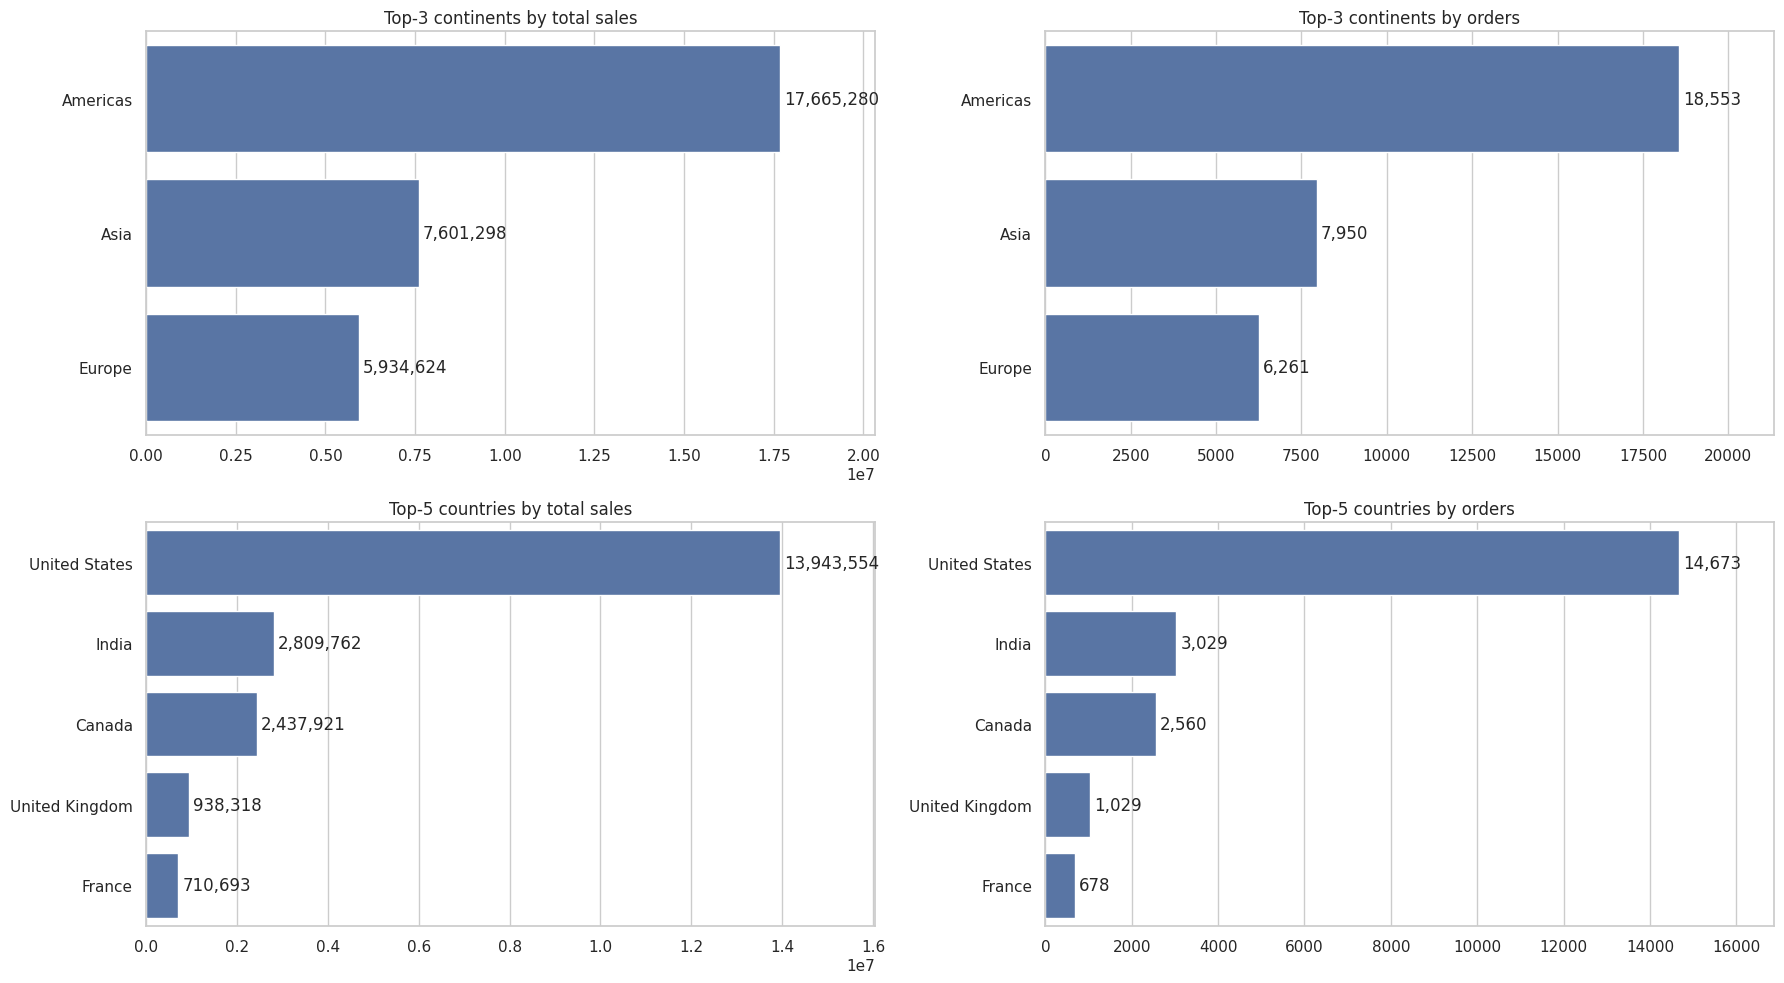

In [54]:
# Sales by continent
continent_stats = (df_orders.groupby("continent")
                   .agg(total_sales=("price", "sum"),
                        orders=("session_id", "nunique"))
                   .reset_index())
continent_stats["sales_share_pct"] = (continent_stats["total_sales"] / continent_stats["total_sales"].sum() * 100).round(2)
continent_stats["orders_share_pct"] = (continent_stats["orders"] / continent_stats["orders"].sum() * 100).round(2)

# Sales by country
country_stats = (df_orders.groupby("country")
                 .agg(total_sales=("price", "sum"),
                      orders=("session_id", "nunique"))
                 .reset_index())
country_stats["sales_share_pct"] = (country_stats["total_sales"] / country_stats["total_sales"].sum() * 100).round(2)
country_stats["orders_share_pct"] = (country_stats["orders"] / country_stats["orders"].sum() * 100).round(2)
country_stats = country_stats[country_stats["country"] != "(not set)"]

# Rankings
top3_continents_sales = continent_stats.nlargest(3, "total_sales")
top3_continents_orders = continent_stats.nlargest(3, "orders")
top5_countries_sales = country_stats.nlargest(5, "total_sales")
top5_countries_orders = country_stats.nlargest(5, "orders")

display(top3_continents_sales)
display(top3_continents_orders)
display(top5_countries_sales)
display(top5_countries_orders)

# Charts
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 2, figsize=(18, 10))

ax = sns.barplot(data=top3_continents_sales, x="total_sales", y="continent", color="#4C72B0", ax=axes[0, 0])
ax.set(title="Top-3 continents by total sales", xlabel="", ylabel="", xmargin=0.15)
ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=3)

ax = sns.barplot(data=top3_continents_orders, x="orders", y="continent", color="#4C72B0", ax=axes[0, 1])
ax.set(title="Top-3 continents by orders", xlabel="", ylabel="", xmargin=0.15)
ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=3)

ax = sns.barplot(data=top5_countries_sales, x="total_sales", y="country", color="#4C72B0", ax=axes[1, 0])
ax.set(title="Top-5 countries by total sales", xlabel="", ylabel="", xmargin=0.15)
ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=3)

ax = sns.barplot(data=top5_countries_orders, x="orders", y="country", color="#4C72B0", ax=axes[1, 1])
ax.set(title="Top-5 countries by orders", xlabel="", ylabel="", xmargin=0.15)
ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=3)

plt.tight_layout()
plt.show()

**Continents.** Americas lead with 17.7M in sales (55.3%) and 18,553 orders, followed by Asia (7.6M, 23.8%) and Europe (5.9M, 18.6%). Together the top-3 continents account for 97.6% of all sales. The ranking by orders is identical to the ranking by sales.

**Countries.** The United States is by far the largest market: 13.9M in sales (43.6% of the total, 14,673 orders), almost 5 times more than second-placed India (2.8M, 8.8%). Canada (2.4M, 7.6%), the United Kingdom (0.9M, 2.9%) and France (0.7M, 2.2%) complete the top-5.

**Observations.** The business is highly concentrated: the US and Canada alone generate about 93% of sales in the Americas, and India accounts for 37% of Asia. Europe is the opposite case: it is the third continent, yet its two largest countries in the ranking (UK and France) make up only 28% of European sales, so the rest is spread across many smaller markets. Shares of sales and orders are almost the same everywhere (e.g. 43.6% vs 43.8% for the US), which means average sales per purchase session is similar across regions (about 950 on each continent) and the ranking is driven by the number of purchases rather than by order value.

### 3.2 Product categories

,product_category,total_sales,orders,sales_share_pct,avg_sales_per_order
12,Sofas & armchairs,8388254.5,4301,26.24,1950.30
5,Chairs,6147748.8,5952,19.23,1032.89
1,Beds,4919725.0,2926,15.39,1681.38
2,Bookcases & shelving units,3640818.1,7630,11.39,477.17
3,Cabinets & cupboards,2336499.5,2318,7.31,1007.98
9,Outdoor furniture,2142222.2,2229,6.70,961.07
13,Tables & desks,1790307.5,2941,5.60,608.74
6,Chests of drawers & drawer units,906562.5,1452,2.84,624.35
0,Bar furniture,735503.0,1092,2.30,673.54
7,Children's furniture,467697.0,1702,1.46,274.79


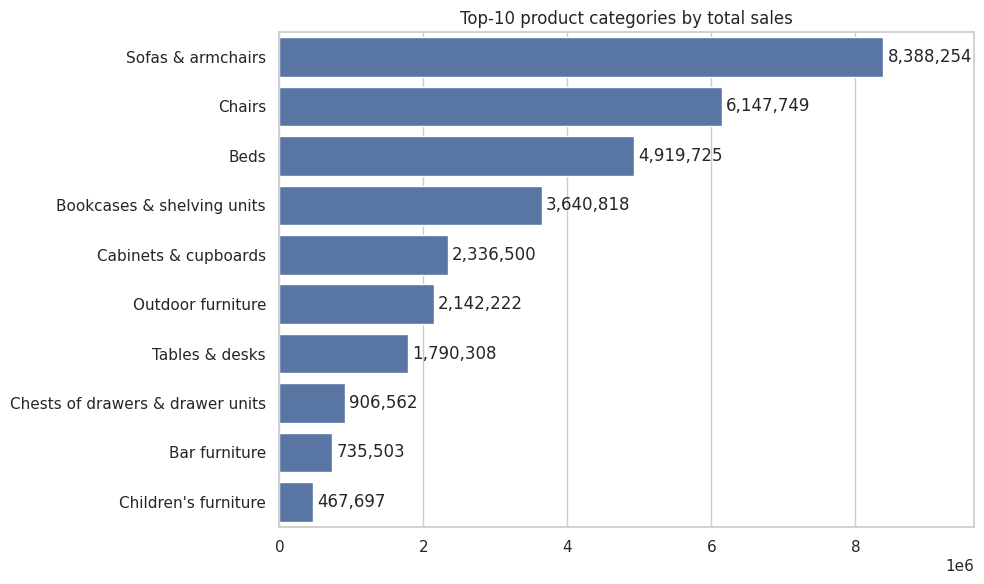

In [55]:
# Sales by product category
category_stats = (df_orders.groupby("product_category")
                  .agg(total_sales=("price", "sum"),
                       orders=("session_id", "nunique"))
                  .reset_index())
category_stats["sales_share_pct"] = (category_stats["total_sales"] / category_stats["total_sales"].sum() * 100).round(2)
category_stats["avg_sales_per_order"] = (category_stats["total_sales"] / category_stats["orders"]).round(2)

top10_categories = category_stats.nlargest(10, "total_sales")
display(top10_categories)

# Chart
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=top10_categories, x="total_sales", y="product_category", color="#4C72B0", ax=ax)
ax.set(title="Top-10 product categories by total sales", xlabel="", ylabel="", xmargin=0.15)
ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=3)
plt.tight_layout()
plt.show()

The top-10 categories account for 98.5% of total sales (the remaining 4 categories add up to only 1.5%). Sales are concentrated in a few categories: Sofas & armchairs (8.4M, 26.2%), Chairs (6.1M, 19.2%) and Beds (4.9M, 15.4%) together generate 60.9% of revenue, and adding Bookcases & shelving units (3.6M, 11.4%) brings it to 72.3%.

The ranking by sales differs from the ranking by orders. Bookcases & shelving units have the largest number of orders (7,630) but are only 4th in sales, because their average sales per order is about 477. Sofas & armchairs are 1st in sales with just 4,301 orders (3rd by orders), thanks to an average of about 1,950 per order. A similar pattern is visible for Children's furniture: 1,702 orders (more than Chests of drawers or Bar furniture), but the lowest sales in the top-10 (about 275 per order). So the leading categories are driven by high prices rather than by popularity.

,product_category,total_sales,orders,sales_share_pct
12,Sofas & armchairs,3707144.5,1903,26.59
5,Chairs,2619773.8,2576,18.79
1,Beds,2213058.0,1298,15.87
2,Bookcases & shelving units,1567606.9,3374,11.24
3,Cabinets & cupboards,994545.5,995,7.13
9,Outdoor furniture,929245.2,984,6.66
13,Tables & desks,777865.0,1248,5.58
6,Chests of drawers & drawer units,382388.0,616,2.74
0,Bar furniture,330805.0,487,2.37
7,Children's furniture,207575.0,752,1.49


,product_category,sales_share_pct_global,sales_share_pct_country,diff_pp,rank_global,rank_country
12,Sofas & armchairs,26.24,26.59,0.35,1,1
5,Chairs,19.23,18.79,-0.44,2,2
1,Beds,15.39,15.87,0.48,3,3
2,Bookcases & shelving units,11.39,11.24,-0.15,4,4
3,Cabinets & cupboards,7.31,7.13,-0.18,5,5
9,Outdoor furniture,6.70,6.66,-0.04,6,6
13,Tables & desks,5.60,5.58,-0.02,7,7
6,Chests of drawers & drawer units,2.84,2.74,-0.10,8,8
0,Bar furniture,2.30,2.37,0.07,9,9
7,Children's furniture,1.46,1.49,0.03,10,10


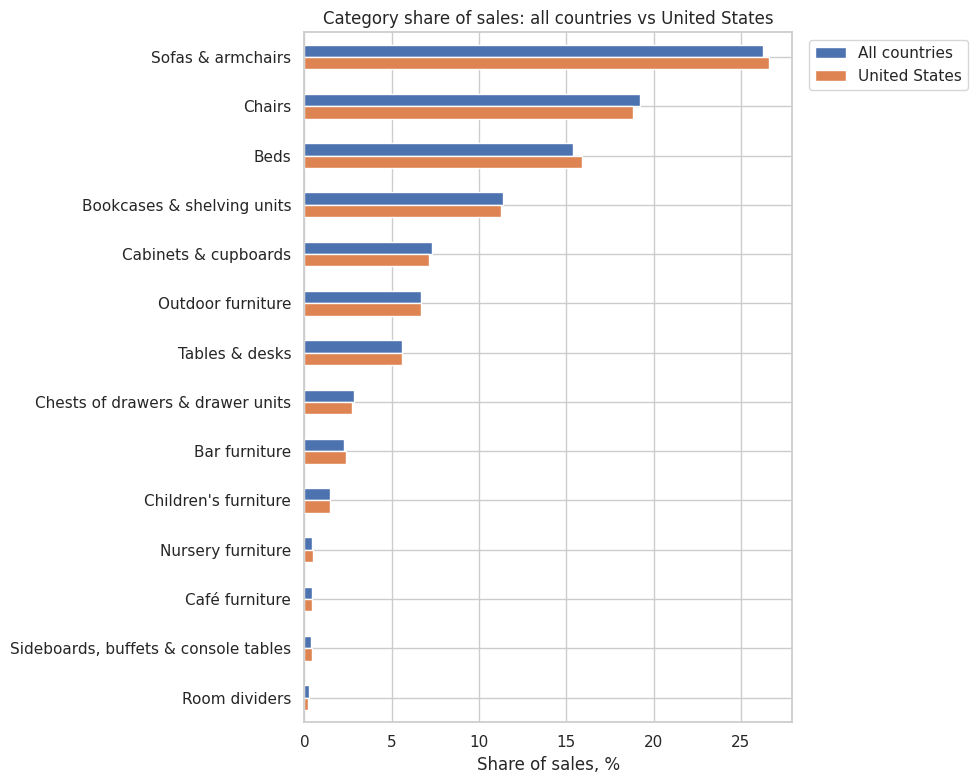

In [56]:
# Sales by product category in the top country
top_country_name = top5_countries_sales["country"].iloc[0]
country_categories = (df_orders[df_orders["country"] == top_country_name]
                      .groupby("product_category")
                      .agg(total_sales=("price", "sum"),
                           orders=("session_id", "nunique"))
                      .reset_index())
country_categories["sales_share_pct"] = (country_categories["total_sales"] / country_categories["total_sales"].sum() * 100).round(2)

top10_country_categories = country_categories.nlargest(10, "total_sales")
display(top10_country_categories)

# Compare category shares: top country vs all countries (difference in percentage points)
comparison = (category_stats[["product_category", "sales_share_pct"]]
              .merge(country_categories[["product_category", "sales_share_pct"]],
                     on="product_category", suffixes=("_global", "_country"))
              .sort_values("sales_share_pct_global", ascending=False))
comparison["diff_pp"] = (comparison["sales_share_pct_country"] - comparison["sales_share_pct_global"]).round(2)
comparison["rank_global"] = comparison["sales_share_pct_global"].rank(ascending=False).astype(int)
comparison["rank_country"] = comparison["sales_share_pct_country"].rank(ascending=False).astype(int)
display(comparison)

# Chart: grouped bars, all countries vs top country
ax = comparison.plot.barh(x="product_category", y=["sales_share_pct_global", "sales_share_pct_country"], figsize=(10, 8))
ax.invert_yaxis()
ax.legend(["All countries", top_country_name], loc="upper left", bbox_to_anchor=(1.02, 1))
ax.set(title=f"Category share of sales: all countries vs {top_country_name}", xlabel="Share of sales, %", ylabel="")
plt.tight_layout()
plt.show()

The top-10 categories in the United States are exactly the same as in the overall picture and appear in the same order (Sofas & armchairs, Chairs, Beds, Bookcases & shelving units, Cabinets & cupboards, ...). The grouped bar chart shows almost identical bars, and the shares differ by less than 0.5 percentage points for every category: the US has a slightly higher share of Beds (+0.48 pp) and Sofas & armchairs (+0.35 pp) and a slightly lower share of Chairs (-0.44 pp) and Cabinets & cupboards (-0.18 pp).

The pattern by orders is also the same as globally: Bookcases & shelving units have the most orders in the US (3,374), but rank only 4th by sales because of their low average price. So the category structure of US sales practically mirrors the global one, which is partly expected, since the US generates 43.6% of all sales and therefore largely defines the overall picture.

### 3.3 Devices and models

,device,total_sales,orders,sales_share_pct,avg_sales_per_order
0,desktop,18864039.0,19702,59.00,957.47
1,mobile,12384225.8,13113,38.73,944.42
2,tablet,723466.3,723,2.26,1000.64


,device,device_model_name,total_sales,orders,sales_share_pct
1,desktop,Chrome,8899523.9,9359,27.84
5,desktop,Safari,6490467.1,6831,20.30
11,mobile,iPhone,6420776.3,6819,20.08
6,mobile,<Other>,5735073.6,6069,17.94
2,desktop,ChromeBook,1830458.7,1877,5.73
3,desktop,Edge,696877.3,740,2.18
0,desktop,<Other>,525645.1,465,1.64
13,tablet,iPad,448854.2,456,1.40
4,desktop,Firefox,421066.9,430,1.32
12,tablet,<Other>,274612.1,267,0.86


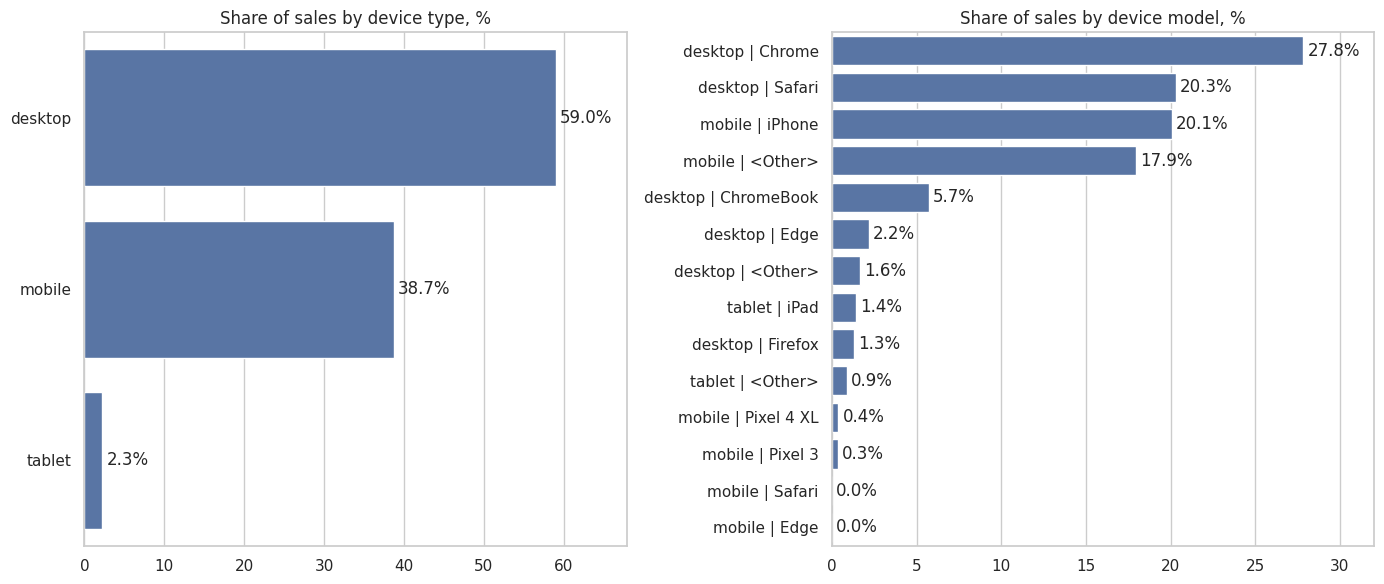

In [57]:
# Sales by device type
device_stats = (df_orders.groupby("device")
                .agg(total_sales=("price", "sum"),
                     orders=("session_id", "nunique"))
                .reset_index())
device_stats["sales_share_pct"] = (device_stats["total_sales"] / device_stats["total_sales"].sum() * 100).round(2)
device_stats["avg_sales_per_order"] = (device_stats["total_sales"] / device_stats["orders"]).round(2)
device_stats = device_stats.sort_values("total_sales", ascending=False)

# Sales by device type + model (model names on desktop may simply repeat the browser name)
model_stats = (df_orders.groupby(["device", "device_model_name"])
               .agg(total_sales=("price", "sum"),
                    orders=("session_id", "nunique"))
               .reset_index())
model_stats["sales_share_pct"] = (model_stats["total_sales"] / model_stats["total_sales"].sum() * 100).round(2)
model_stats = model_stats.sort_values("total_sales", ascending=False)

display(device_stats)
display(model_stats)

# Charts
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ax = sns.barplot(data=device_stats, x="sales_share_pct", y="device", color="#4C72B0", ax=axes[0])
ax.set(title="Share of sales by device type, %", xlabel="", ylabel="", xmargin=0.15)
ax.bar_label(ax.containers[0], fmt="{:.1f}%", padding=3)

model_stats["device_model"] = model_stats["device"] + " | " + model_stats["device_model_name"]
ax = sns.barplot(data=model_stats, x="sales_share_pct", y="device_model", color="#4C72B0", ax=axes[1])
ax.set(title="Share of sales by device model, %", xlabel="", ylabel="", xmargin=0.15)
ax.bar_label(ax.containers[0], fmt="{:.1f}%", padding=3)

plt.tight_layout()
plt.show()

**Device type.** Desktop generates 59.0% of sales (18.9M, 19,702 orders), mobile 38.7% (12.4M, 13,113 orders) and tablet only 2.3% (0.7M, 723 orders). Average sales per order is similar across device types (about 957 on desktop, 944 on mobile and 1,001 on tablet; the tablet figure rests on only 723 orders), so the differences in total sales come mainly from the number of purchases rather than from order value.

**Device model.** The `device_model_name` column mixes different kinds of values: for desktop it contains browser names (Chrome, Safari, Edge, Firefox) plus ChromeBook, for mobile it contains real models (iPhone, Pixel 3, Pixel 4 XL), and for tablets it is iPad or unknown. The shares by "model" should therefore be read within each device type. On desktop, Chrome (27.8% of all sales, 47% of desktop sales) and Safari (20.3%, 34% of desktop sales) dominate. On mobile, iPhone accounts for 20.1% of all sales (52% of mobile sales), while the two Google Pixel models add up to only 0.7%. An important limitation: 20.4% of all sales have an unknown model (`<Other>`), about 88% of them on mobile, so for 46% of mobile sales the exact model is not identified and conclusions about mobile models are limited.

### 3.4 Traffic channels

,traffic_channel,total_sales,orders,sales_share_pct,avg_sales_per_order
1,Organic Search,11433151.6,11921,35.76,959.08
2,Paid Search,8511049.4,9042,26.62,941.28
0,Direct,7494923.4,7800,23.44,960.89
3,Social Search,2532105.7,2716,7.92,932.29
4,Undefined,2000501.0,2059,6.26,971.59


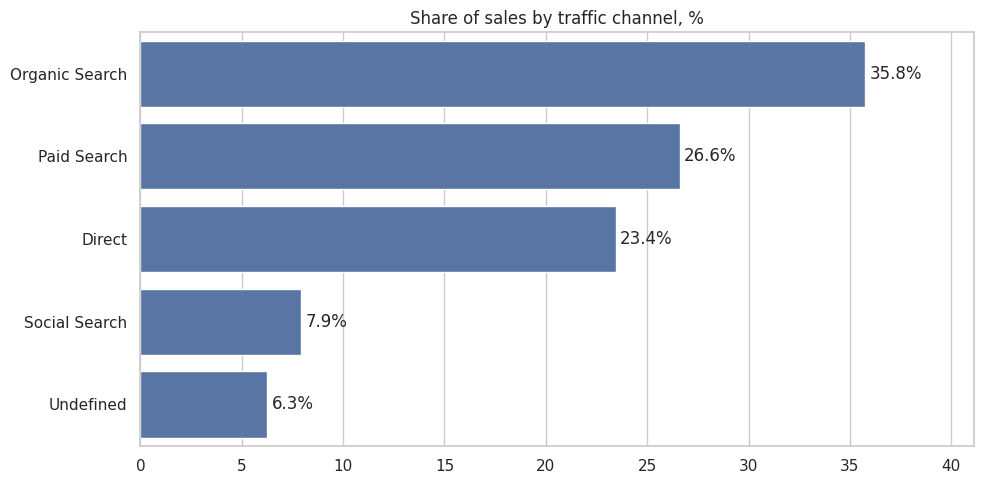

In [58]:
# Sales by traffic channel
channel_stats = (df_orders.groupby("traffic_channel")
                 .agg(total_sales=("price", "sum"),
                      orders=("session_id", "nunique"))
                 .reset_index())
channel_stats["sales_share_pct"] = (channel_stats["total_sales"] / channel_stats["total_sales"].sum() * 100).round(2)
channel_stats["avg_sales_per_order"] = (channel_stats["total_sales"] / channel_stats["orders"]).round(2)
channel_stats = channel_stats.sort_values("total_sales", ascending=False)
display(channel_stats)

# Chart
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=channel_stats, x="sales_share_pct", y="traffic_channel", color="#4C72B0", ax=ax)
ax.set(title="Share of sales by traffic channel, %", xlabel="", ylabel="", xmargin=0.15)
ax.bar_label(ax.containers[0], fmt="{:.1f}%", padding=3)
plt.tight_layout()
plt.show()

Organic Search is the largest traffic channel with 35.8% of sales (11.4M, 11,921 orders), followed by Paid Search (26.6%, 8.5M) and Direct (23.4%, 7.5M). These three channels generate 85.8% of all sales, and the two search channels alone account for 62.4%. Social Search brings 7.9%, while 6.3% of sales (2.0M) come from sessions with an undefined channel, so the origin of that revenue is unknown. Average sales per order are very similar across channels (from about 932 to 972), so the differences in total sales are driven by the number of purchases rather than by order value.


### 3.5 Registered users

Registered users: 27,945
Email confirmed: 71.7%
Unsubscribed from newsletter: 16.9%


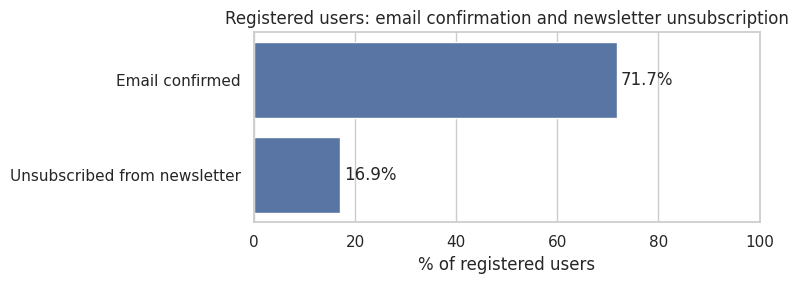

In [59]:
# One row per registered user
registered_users = df.dropna(subset=["registered_user_id"]).drop_duplicates("registered_user_id")

email_confirmed_pct = registered_users["is_email_confirmed"].mean() * 100
newsletter_unsub_pct = registered_users["is_newsletter_unsubscribed"].mean() * 100

print(f"Registered users: {len(registered_users):,}")
print(f"Email confirmed: {email_confirmed_pct:.1f}%")
print(f"Unsubscribed from newsletter: {newsletter_unsub_pct:.1f}%")

# Chart
engagement = pd.DataFrame({"metric": ["Email confirmed", "Unsubscribed from newsletter"],
                           "pct": [email_confirmed_pct, newsletter_unsub_pct]})

fig, ax = plt.subplots(figsize=(8, 3))
sns.barplot(data=engagement, x="pct", y="metric", color="#4C72B0", ax=ax)
ax.set(title="Registered users: email confirmation and newsletter unsubscription",
       xlabel="% of registered users", ylabel="", xlim=(0, 100))
ax.bar_label(ax.containers[0], fmt="{:.1f}%", padding=3)
plt.tight_layout()
plt.show()

The data contains 27,945 registered users. 71.7% of them confirmed their email address (so 28.3% did not), and 16.9% unsubscribed from the newsletter (83.1% are still subscribed). Each registered user appears in the dataset only once (the number of unique `registered_user_id` values equals the number of rows with a non-empty `registered_user_id`).

,country,registered_users,share_pct
104,United States,12384,44.32
43,India,2687,9.62
18,Canada,2067,7.40
103,United Kingdom,859,3.07
33,France,553,1.98
92,Spain,536,1.92
96,Taiwan,500,1.79
20,China,490,1.75
35,Germany,490,1.75
48,Italy,386,1.38


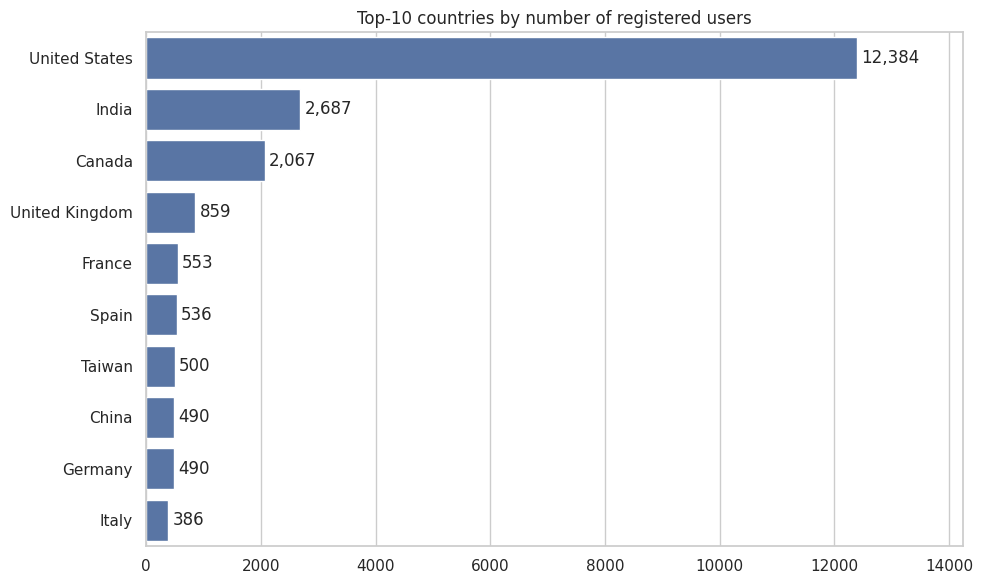

In [60]:
# Registered users by country
registered_by_country = (registered_users.groupby("country")
                         .agg(registered_users=("registered_user_id", "nunique"))
                         .reset_index())
registered_by_country["share_pct"] = (registered_by_country["registered_users"] / registered_by_country["registered_users"].sum() * 100).round(2)

top10_registered = (registered_by_country[registered_by_country["country"] != "(not set)"]
                    .nlargest(10, "registered_users"))
display(top10_registered)

# Chart
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=top10_registered, x="registered_users", y="country", color="#4C72B0", ax=ax)
ax.set(title="Top-10 countries by number of registered users", xlabel="", ylabel="", xmargin=0.15)
ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=3)
plt.tight_layout()
plt.show()

The United States has by far the most registered users: 12,384, or 44.3% of all registered users. It is followed by India (2,687, 9.6%), Canada (2,067, 7.4%), the United Kingdom (859, 3.1%) and France (553, 2.0%). These five countries are exactly the same as the top-5 countries by sales, and in the same order. The top-3 countries account for 61.3% of registered users and the top-10 for about 75%; countries ranked 6th to 10th (Spain, Taiwan, China, Germany, Italy) each contribute only 1.4-1.9%.

The share of each country among registered users is close to its share of sales (for example, the US has 44.3% of registered users and 43.6% of sales, India 9.6% and 8.8%), so registrations are concentrated in the same markets as revenue.

### 3.6 Subscribed vs unsubscribed users

,is_newsletter_unsubscribed,users,sessions_with_purchase,total_sales,avg_sales_per_order,group,purchase_rate_pct,sales_per_user
0,0.0,23210,2334,2150796.9,921.51,Subscribed,10.06,92.67
1,1.0,4735,447,431721.6,965.82,Unsubscribed,9.44,91.18


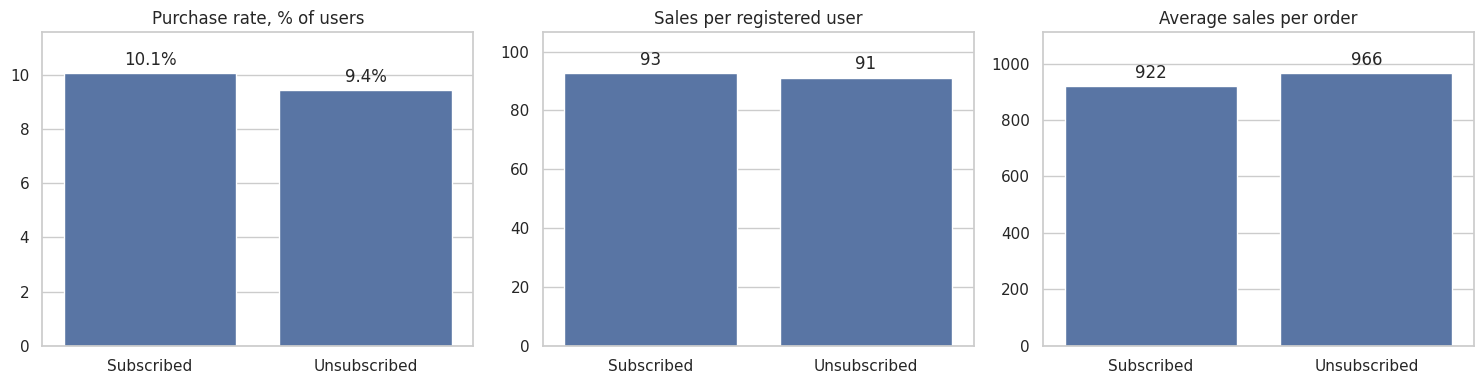

In [61]:
subscription_stats = (registered_users.groupby("is_newsletter_unsubscribed")
                      .agg(users=("registered_user_id", "nunique"),
                           sessions_with_purchase=("price", "count"),
                           total_sales=("price", "sum"),
                           avg_sales_per_order=("price", "mean"))
                      .reset_index())
subscription_stats["group"] = subscription_stats["is_newsletter_unsubscribed"].map({0.0: "Subscribed", 1.0: "Unsubscribed"})
subscription_stats["purchase_rate_pct"] = (subscription_stats["sessions_with_purchase"] / subscription_stats["users"] * 100).round(2)
subscription_stats["sales_per_user"] = (subscription_stats["total_sales"] / subscription_stats["users"]).round(2)
subscription_stats["avg_sales_per_order"] = subscription_stats["avg_sales_per_order"].round(2)
display(subscription_stats)

# Charts
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

ax = sns.barplot(data=subscription_stats, x="group", y="purchase_rate_pct", color="#4C72B0", ax=axes[0])
ax.set(title="Purchase rate, % of users", xlabel="", ylabel="", ymargin=0.15)
ax.bar_label(ax.containers[0], fmt="{:.1f}%", padding=3)

ax = sns.barplot(data=subscription_stats, x="group", y="sales_per_user", color="#4C72B0", ax=axes[1])
ax.set(title="Sales per registered user", xlabel="", ylabel="", ymargin=0.15)
ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=3)

ax = sns.barplot(data=subscription_stats, x="group", y="avg_sales_per_order", color="#4C72B0", ax=axes[2])
ax.set(title="Average sales per order", xlabel="", ylabel="", ymargin=0.15)
ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=3)

plt.tight_layout()
plt.show()

Users who unsubscribed from the newsletter (4,735 users, 16.9% of registered users) behave almost the same as subscribers (23,210 users). The share of users who made a purchase is 10.1% among subscribers and 9.4% among unsubscribers (a difference of 0.6 percentage points), and average sales per registered user are 92.7 and 91.2 respectively. Unsubscribers who bought have a slightly higher average order (966 vs 922, +4.8%), but this is based on only 447 buyers, so it is a weak signal. Unsubscribers generate 16.7% of the sales made by registered users, which is almost exactly their share among users (16.9%).

Overall, unsubscribing from the newsletter does not appear to be associated with a meaningful difference in purchasing behavior.

Note that each registered user appears in the data with a single session, so repeat purchases are not visible.

### 3.7 Conversion by channel, device and country

,traffic_channel,sessions,registered,purchases,registration_rate_pct,purchase_rate_pct
3,Social Search,26816,2212,2716,8.25,10.13
0,Direct,78178,6514,7800,8.33,9.98
2,Paid Search,90730,7467,9042,8.23,9.97
1,Organic Search,119687,10035,11921,8.38,9.96
4,Undefined,20665,1717,2059,8.31,9.96


,device,sessions,registered,purchases,registration_rate_pct,purchase_rate_pct
0,desktop,196577,16417,19702,8.35,10.02
1,mobile,131955,10878,13113,8.24,9.94
2,tablet,7544,650,723,8.62,9.58


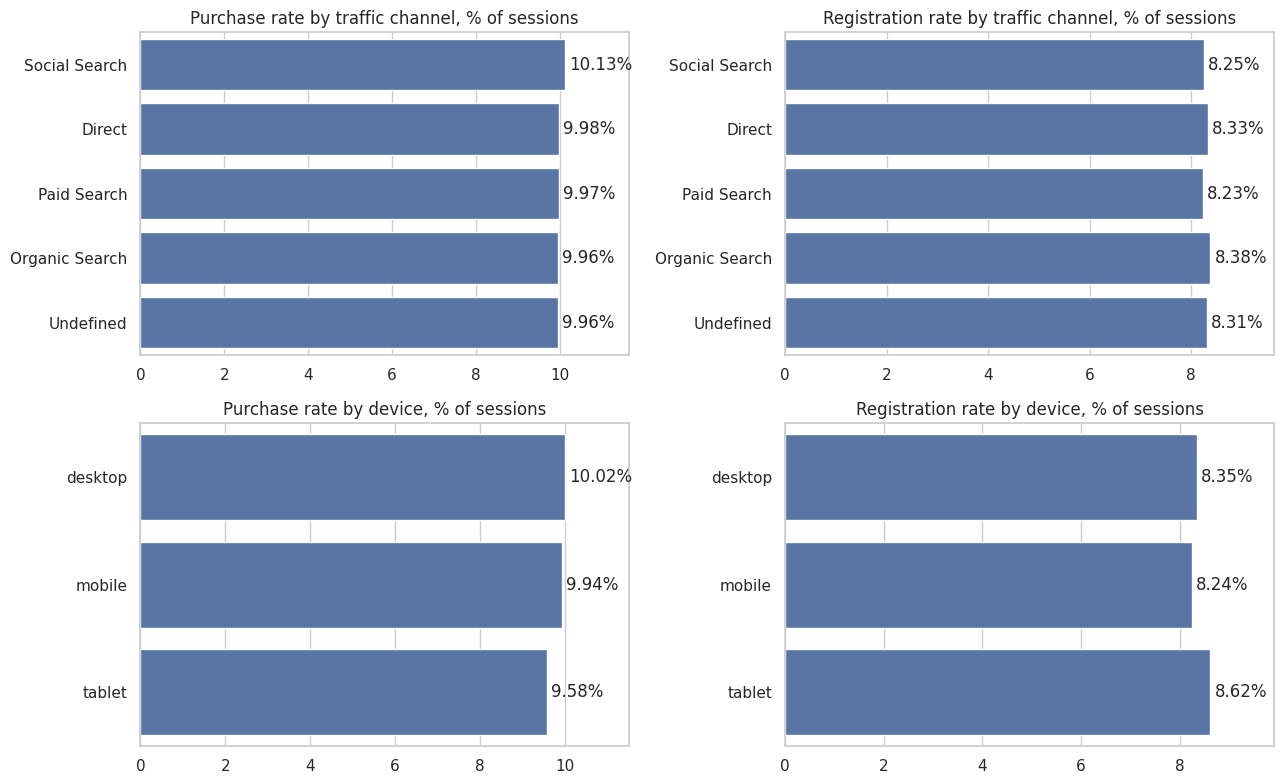

In [62]:
# Funnel by traffic channel: sessions -> registrations -> purchases
channel_conversion = (df.groupby("traffic_channel")
                      .agg(sessions=("session_id", "nunique"),
                           registered=("registered_user_id", "nunique"),   # unique registered users
                           purchases=("price", "count"))                   # sessions with a purchase
                      .reset_index())
channel_conversion["registration_rate_pct"] = (channel_conversion["registered"] / channel_conversion["sessions"] * 100).round(2)
channel_conversion["purchase_rate_pct"] = (channel_conversion["purchases"] / channel_conversion["sessions"] * 100).round(2)
channel_conversion = channel_conversion.sort_values("purchase_rate_pct", ascending=False)

# Funnel by device type
device_conversion = (df.groupby("device")
                     .agg(sessions=("session_id", "nunique"),
                          registered=("registered_user_id", "nunique"),
                          purchases=("price", "count"))
                     .reset_index())
device_conversion["registration_rate_pct"] = (device_conversion["registered"] / device_conversion["sessions"] * 100).round(2)
device_conversion["purchase_rate_pct"] = (device_conversion["purchases"] / device_conversion["sessions"] * 100).round(2)
device_conversion = device_conversion.sort_values("purchase_rate_pct", ascending=False)

display(channel_conversion)
display(device_conversion)

# Charts
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

ax = sns.barplot(data=channel_conversion, x="purchase_rate_pct", y="traffic_channel", color="#4C72B0", ax=axes[0, 0])
ax.set(title="Purchase rate by traffic channel, % of sessions", xlabel="", ylabel="", xmargin=0.15)
ax.bar_label(ax.containers[0], fmt="{:.2f}%", padding=3)

ax = sns.barplot(data=channel_conversion, x="registration_rate_pct", y="traffic_channel", color="#4C72B0", ax=axes[0, 1])
ax.set(title="Registration rate by traffic channel, % of sessions", xlabel="", ylabel="", xmargin=0.15)
ax.bar_label(ax.containers[0], fmt="{:.2f}%", padding=3)

ax = sns.barplot(data=device_conversion, x="purchase_rate_pct", y="device", color="#4C72B0", ax=axes[1, 0])
ax.set(title="Purchase rate by device, % of sessions", xlabel="", ylabel="", xmargin=0.15)
ax.bar_label(ax.containers[0], fmt="{:.2f}%", padding=3)

ax = sns.barplot(data=device_conversion, x="registration_rate_pct", y="device", color="#4C72B0", ax=axes[1, 1])
ax.set(title="Registration rate by device, % of sessions", xlabel="", ylabel="", xmargin=0.15)
ax.bar_label(ax.containers[0], fmt="{:.2f}%", padding=3)

plt.tight_layout()
plt.show()

**Traffic channels.** The purchase rate is almost the same in every channel: about 10.0% for Direct, Organic Search, Paid Search and Undefined, and 10.1% for Social Search. The registration rate is also very close, from 8.23% to 8.38%. So the traffic channel has almost no effect on conversion.

**Devices.** Desktop (10.02%) and mobile (9.94%) convert practically equally. Tablet is slightly lower (9.58%), but it is the smallest segment (7,544 sessions), so the gap of about 0.4 percentage points is likely random. The registration rate is about 8.3% on every device (8.24% to 8.62%).

Overall, about 10.0% of sessions end with a purchase and about 8.3% with a registration, regardless of channel or device.

,country,sessions,registered,purchases,registration_rate_pct,purchase_rate_pct
104,United States,147499,12384,14673,8.40,9.95
43,India,31493,2687,3029,8.53,9.62
18,Canada,25021,2067,2560,8.26,10.23
103,United Kingdom,10598,859,1029,8.11,9.71
33,France,6705,553,678,8.25,10.11
92,Spain,6255,536,658,8.57,10.52
35,Germany,5987,490,642,8.18,10.72
20,China,5830,490,600,8.40,10.29
96,Taiwan,5665,500,564,8.83,9.96
48,Italy,4666,386,442,8.27,9.47


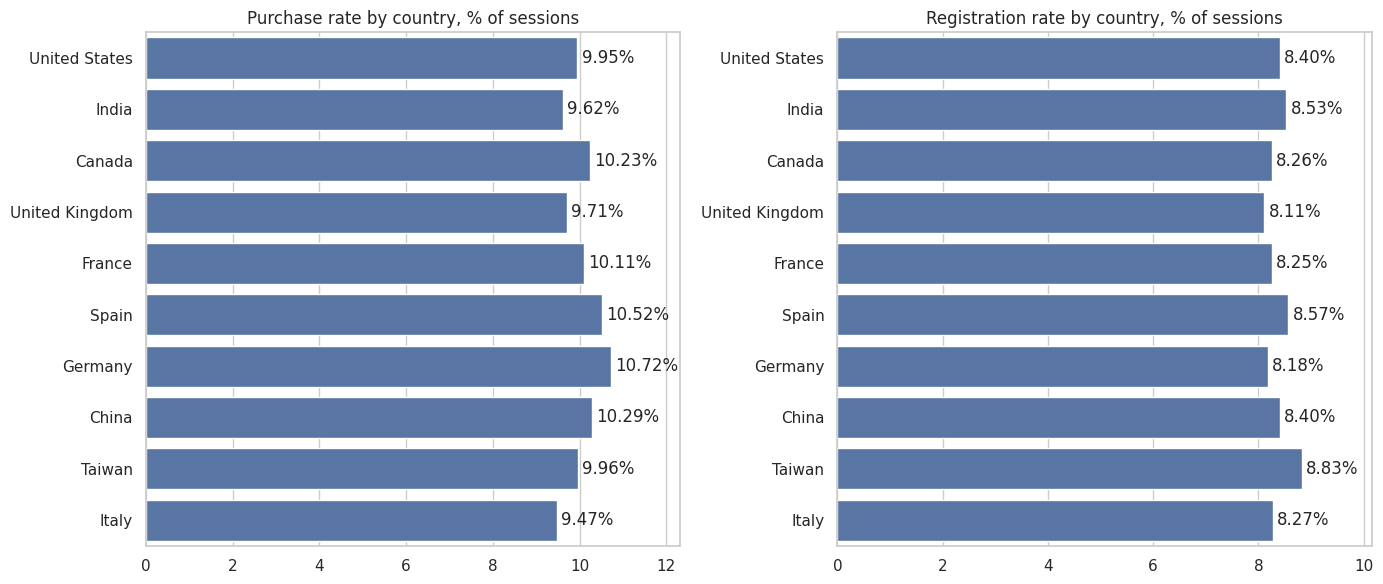

In [63]:
# Funnel by country: sessions -> registrations -> purchases
country_conversion = (df.groupby("country")
                      .agg(sessions=("session_id", "nunique"),
                           registered=("registered_user_id", "nunique"),   # unique registered users
                           purchases=("price", "count"))                   # sessions with a purchase
                      .reset_index())
country_conversion["registration_rate_pct"] = (country_conversion["registered"] / country_conversion["sessions"] * 100).round(2)
country_conversion["purchase_rate_pct"] = (country_conversion["purchases"] / country_conversion["sessions"] * 100).round(2)

# Top-10 countries by traffic ("(not set)" excluded; small countries have unstable rates)
top10_country_conversion = (country_conversion[country_conversion["country"] != "(not set)"]
                            .nlargest(10, "sessions"))
display(top10_country_conversion)

# Charts
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ax = sns.barplot(data=top10_country_conversion, x="purchase_rate_pct", y="country", color="#4C72B0", ax=axes[0])
ax.set(title="Purchase rate by country, % of sessions", xlabel="", ylabel="", xmargin=0.15)
ax.bar_label(ax.containers[0], fmt="{:.2f}%", padding=3)

ax = sns.barplot(data=top10_country_conversion, x="registration_rate_pct", y="country", color="#4C72B0", ax=axes[1])
ax.set(title="Registration rate by country, % of sessions", xlabel="", ylabel="", xmargin=0.15)
ax.bar_label(ax.containers[0], fmt="{:.2f}%", padding=3)

plt.tight_layout()
plt.show()

**Countries.** Conversion is similar across the top-10 countries. The purchase rate ranges from 9.47% (Italy) to 10.72% (Germany), and the United States (9.95%) is almost exactly at the site average of about 10.0%. The registration rate is even more uniform, from 8.11% (United Kingdom) to 8.83% (Taiwan).

## 4. Sales Dynamics and Seasonality

In this section, we study how sales change over time between November 1, 2020 and January 27, 2021. We start with total daily sales, then check for weekly patterns and the effect of holidays and shopping events (Black Friday, Cyber Monday, Christmas, New Year). Finally, we compare the dynamics across continents, traffic channels and device types.

### 4.1 Total sales by date

,session_date,total_sales,orders,sales_7d_avg
37,2020-12-08,680509.5,689,492342.542857
39,2020-12-10,624104.6,597,507177.800000
66,2021-01-06,609763.8,579,403682.271429
45,2020-12-16,553134.9,526,455775.957143
38,2020-12-09,551811.6,588,505259.971429


,total_sales
count,88.0
mean,363315.0
std,100327.0
min,200892.0
25%,294145.0
50%,345354.0
75%,420637.0
max,680510.0


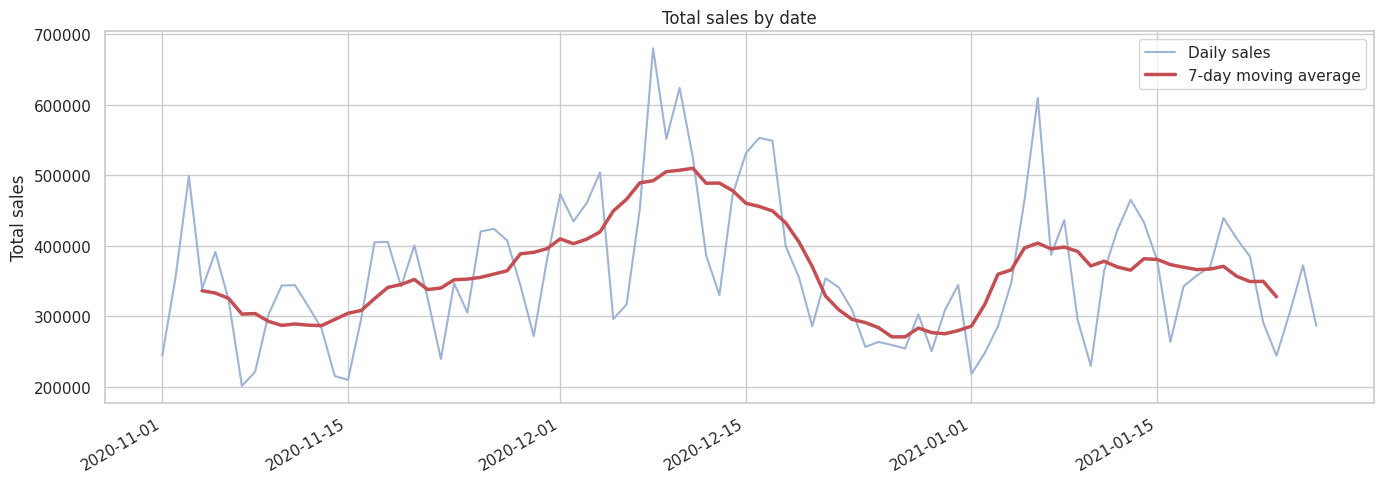

In [64]:
# Total sales and orders per date
daily_sales = (df_orders.groupby("session_date")
               .agg(total_sales=("price", "sum"),
                    orders=("session_id", "nunique"))
               .reset_index())

# 7-day moving average smooths the daily noise
daily_sales["sales_7d_avg"] = daily_sales["total_sales"].rolling(7, center=True).mean()

display(daily_sales.nlargest(5, "total_sales"))   # best days
display(daily_sales["total_sales"].describe().round(0))

# Chart
fig, ax = plt.subplots(figsize=(14, 5))
sns.lineplot(data=daily_sales, x="session_date", y="total_sales", color="#9DB4D6", label="Daily sales", ax=ax)
sns.lineplot(data=daily_sales, x="session_date", y="sales_7d_avg", color="#C44E52", linewidth=2.5, label="7-day moving average", ax=ax)
ax.set(title="Total sales by date", xlabel="", ylabel="Total sales")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

Daily sales fluctuate strongly: the average day brings about 363k (median 345k), with a range from 201k to 681k. The best day is December 8, 2020 (680.5k, 689 orders), and three of the five best days fall on December 8-10; the other two are December 16 and January 6.

The 7-day moving average shows several phases: it starts at about 300-350k in early November, rises to a peak of about 510k in the second week of December, falls to its lowest level (about 270k) around Christmas and the turn of the year, recovers to about 400k in early January and then slowly declines to about 330k by the end of the period. Black Friday and Cyber Monday are not among the five best days.

### 4.2 Seasonality: days of the week and events

,weekday,avg_daily_sales,days,vs_overall_avg_pct
0,Monday,356637.723077,13,-1.8
1,Tuesday,419808.915385,13,15.5
2,Wednesday,420503.300000,13,15.7
3,Thursday,411411.300000,12,13.2
4,Friday,376922.266667,12,3.7
5,Saturday,289832.575000,12,-20.2
6,Sunday,267183.707692,13,-26.5


,session_date,event,total_sales,sales_7d_avg,vs_7d_avg_pct
26,2020-11-27,Black Friday,407338.5,364508.142857,11.8
29,2020-11-30,Cyber Monday,379928.2,395868.985714,-4.0
53,2020-12-24,Christmas Eve,256319.2,290907.042857,-11.9
54,2020-12-25,Christmas Day,263346.4,283584.728571,-7.1
60,2020-12-31,New Year's Eve,344136.2,279476.171429,23.1
61,2021-01-01,New Year's Day,217984.9,285852.314286,-23.7


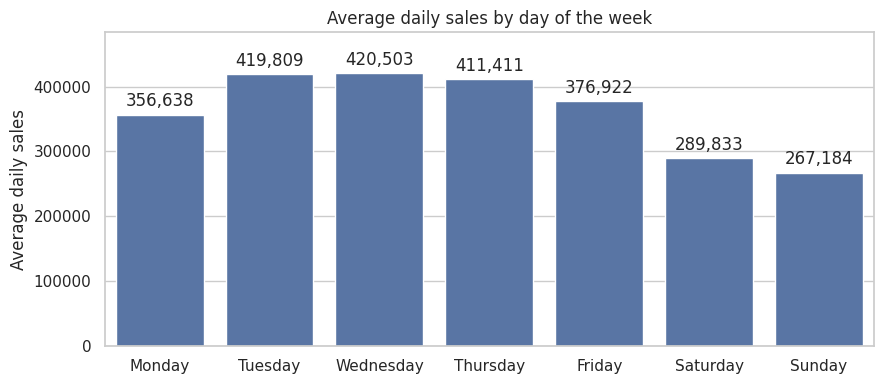

In [65]:
# Average sales by day of the week
daily_sales["weekday"] = daily_sales["session_date"].dt.day_name()
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_sales = (daily_sales.groupby("weekday")
                 .agg(avg_daily_sales=("total_sales", "mean"),
                      days=("total_sales", "count"))
                 .reindex(weekday_order)
                 .reset_index())
weekday_sales["vs_overall_avg_pct"] = ((weekday_sales["avg_daily_sales"] / daily_sales["total_sales"].mean() - 1) * 100).round(1)
display(weekday_sales)

# Holidays and shopping events vs the surrounding 7-day average
event_names = {"2020-11-27": "Black Friday", "2020-11-30": "Cyber Monday", "2020-12-24": "Christmas Eve",
               "2020-12-25": "Christmas Day", "2020-12-31": "New Year's Eve", "2021-01-01": "New Year's Day"}
events = daily_sales[daily_sales["session_date"].isin(pd.to_datetime(list(event_names)))].copy()
events["event"] = events["session_date"].dt.strftime("%Y-%m-%d").map(event_names)
events["vs_7d_avg_pct"] = ((events["total_sales"] / events["sales_7d_avg"] - 1) * 100).round(1)
display(events[["session_date", "event", "total_sales", "sales_7d_avg", "vs_7d_avg_pct"]])

# Chart
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=weekday_sales, x="weekday", y="avg_daily_sales", color="#4C72B0", ax=ax)
ax.set(title="Average daily sales by day of the week", xlabel="", ylabel="Average daily sales", ymargin=0.15)
ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=3)
plt.tight_layout()
plt.show()

**Day of the week.** Sales follow a clear weekly pattern: Tuesday to Thursday are the strongest days (about 410-420k per day, 13-16% above the average), Monday and Friday are close to the average, and the weekend is the weakest, with Saturday (290k) and Sunday (267k) 20% and 26% below the average. On average, a weekend day brings about 30% less than a weekday.

**Holidays and shopping events.** Compared with the surrounding 7-day average, Black Friday was 12% higher and Cyber Monday 4% lower, so neither stands out clearly. Sales dipped on Christmas Eve (-12%), Christmas Day (-7%) and New Year's Day (-24%), while New Year's Eve was 23% higher. The biggest peak of the period (December 8-10) does not coincide with any of these events.

So the data show a clear weekly seasonality and a holiday effect at the end of the year; a yearly seasonality cannot be assessed with only 88 days.

### 4.3 Dynamics by continent

,continent,session_date,total_sales
198,Americas,2021-01-06,374614.9
112,Asia,2020-12-08,164164.8
113,Europe,2020-12-08,150175.1


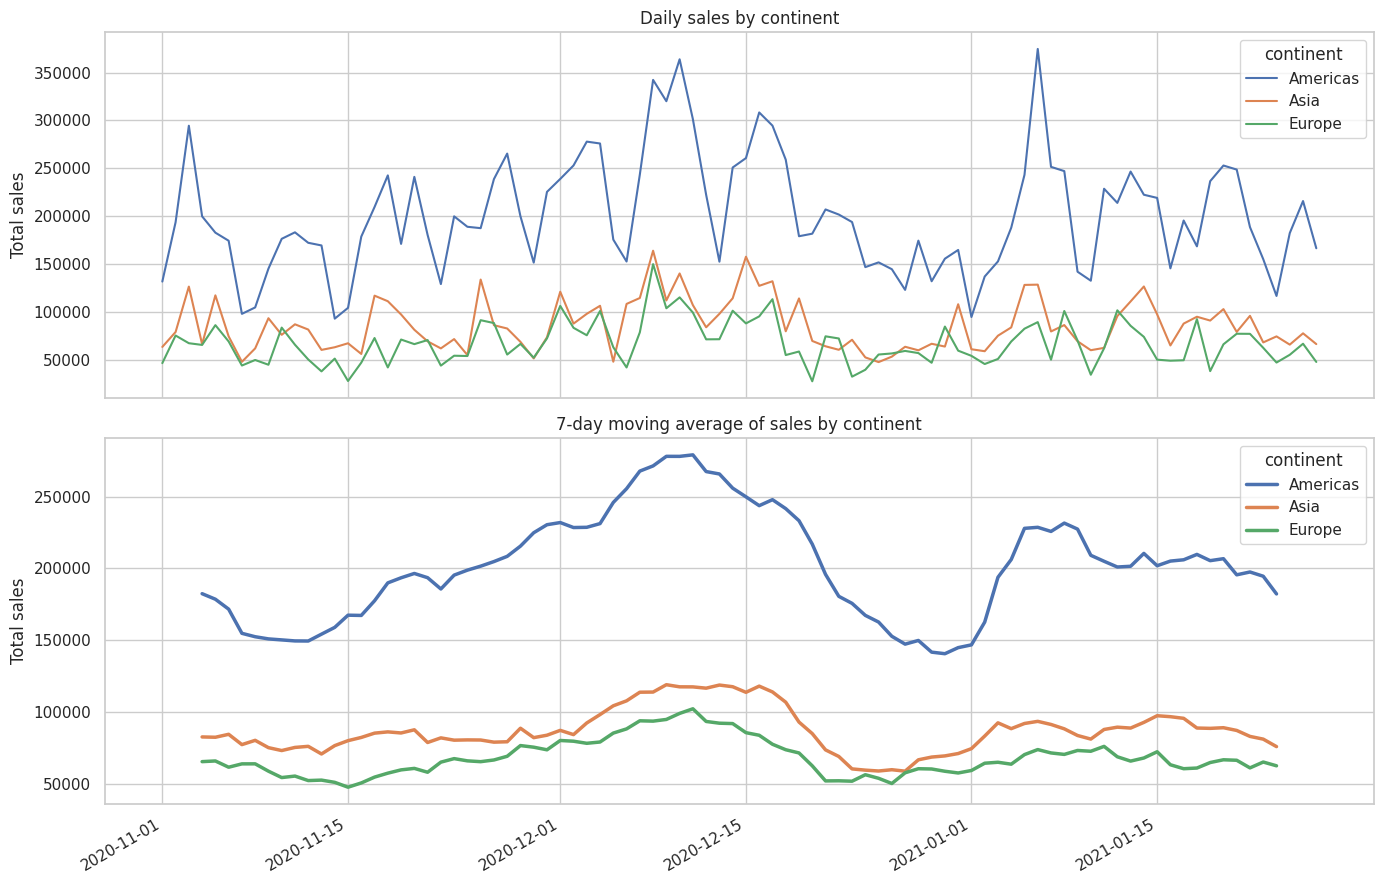

In [66]:
# Daily sales for the top-3 continents
daily_continent = (df_orders[df_orders["continent"].isin(top3_continents_sales["continent"])]
                   .groupby(["session_date", "continent"])
                   .agg(total_sales=("price", "sum"))
                   .reset_index())

# 7-day moving average, calculated separately for each continent
daily_continent["sales_7d_avg"] = (daily_continent.groupby("continent")["total_sales"]
                                   .rolling(7, center=True).mean()
                                   .reset_index(level=0, drop=True))

# Best day for each continent
display(daily_continent.loc[daily_continent.groupby("continent")["total_sales"].idxmax(),
                            ["continent", "session_date", "total_sales"]])

# Charts
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

sns.lineplot(data=daily_continent, x="session_date", y="total_sales", hue="continent", ax=axes[0])
axes[0].set(title="Daily sales by continent", xlabel="", ylabel="Total sales")

sns.lineplot(data=daily_continent, x="session_date", y="sales_7d_avg", hue="continent", linewidth=2.5, ax=axes[1])
axes[1].set(title="7-day moving average of sales by continent", xlabel="", ylabel="Total sales")

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

All three continents follow the same pattern over time. Their 7-day averages rise from early November to a peak in the second week of December, fall by roughly half by the end of December, and recover in January without reaching the December peak. Asia and Europe had their best day on December 8 (164k and 150k), the same day as the overall peak, while the Americas had their best day on January 6 (375k). The Americas stay far ahead throughout, with more than twice the sales of Asia, and Asia remains slightly above Europe in the 7-day average.

### 4.4 Dynamics by traffic channel

,traffic_channel,session_date,total_sales
330,Direct,2021-01-06,157799.5
186,Organic Search,2020-12-08,270436.6
187,Paid Search,2020-12-08,203608.1
228,Social Search,2020-12-16,60074.0
89,Undefined,2020-11-18,62287.4


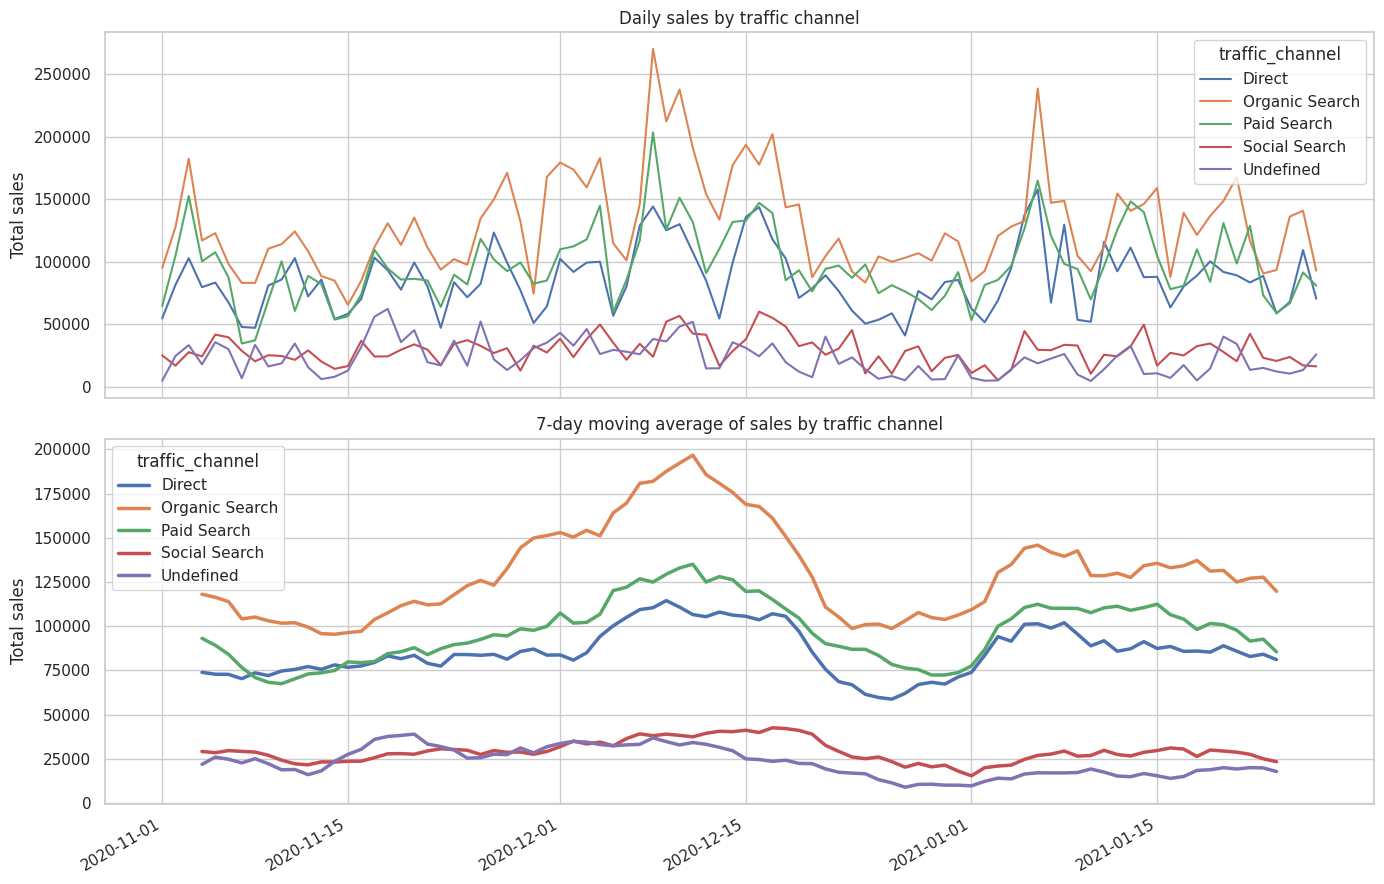

In [67]:
# Daily sales by traffic channel
daily_channel = (df_orders.groupby(["session_date", "traffic_channel"])
                 .agg(total_sales=("price", "sum"))
                 .reset_index())

# 7-day moving average, calculated separately for each channel
daily_channel["sales_7d_avg"] = (daily_channel.groupby("traffic_channel")["total_sales"]
                                 .rolling(7, center=True).mean()
                                 .reset_index(level=0, drop=True))

# Best day for each channel
display(daily_channel.loc[daily_channel.groupby("traffic_channel")["total_sales"].idxmax(),
                          ["traffic_channel", "session_date", "total_sales"]])

# Charts
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

sns.lineplot(data=daily_channel, x="session_date", y="total_sales", hue="traffic_channel", ax=axes[0])
axes[0].set(title="Daily sales by traffic channel", xlabel="", ylabel="Total sales")

sns.lineplot(data=daily_channel, x="session_date", y="sales_7d_avg", hue="traffic_channel", linewidth=2.5, ax=axes[1])
axes[1].set(title="7-day moving average of sales by traffic channel", xlabel="", ylabel="Total sales")

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

The three largest channels (Organic Search, Paid Search and Direct) follow the same pattern: sales rise from early November to a peak around December 8-12, fall to their lowest level around Christmas and recover in early January. Organic Search is the top channel throughout and has the biggest swings: its 7-day average roughly doubles, from about 100k in mid-November to about 197k in the second week of December. Paid Search and Direct are close to each other, with Paid Search ahead from December on. Social Search and Undefined stay low (below 45k per day) and move much less.

Organic Search and Paid Search had their best day on December 8, the same day as the overall peak, while the best day for Direct was January 6, the same date as the best day for the Americas in the previous section.

### 4.5 Dynamics by device type

,device,session_date,total_sales
111,desktop,2020-12-08,394823.7
112,mobile,2020-12-08,258433.8
113,tablet,2020-12-08,27252.0


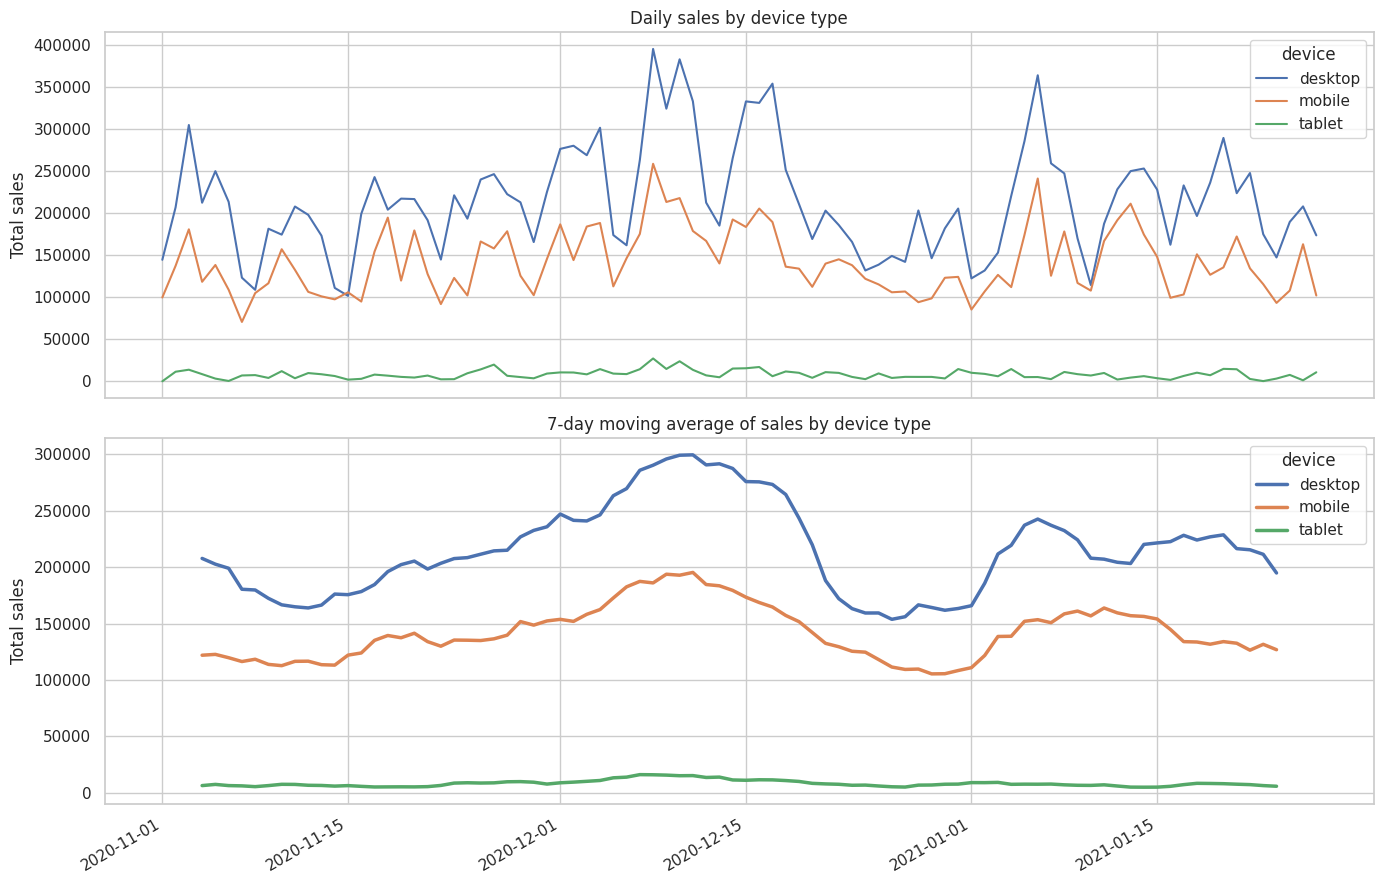

In [68]:
# Daily sales by device type
daily_device = (df_orders.groupby(["session_date", "device"])
                .agg(total_sales=("price", "sum"))
                .reset_index())

# 7-day moving average, calculated separately for each device type
daily_device["sales_7d_avg"] = (daily_device.groupby("device")["total_sales"]
                                .rolling(7, center=True).mean()
                                .reset_index(level=0, drop=True))

# Best day for each device type
display(daily_device.loc[daily_device.groupby("device")["total_sales"].idxmax(),
                         ["device", "session_date", "total_sales"]])

# Charts
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

sns.lineplot(data=daily_device, x="session_date", y="total_sales", hue="device", ax=axes[0])
axes[0].set(title="Daily sales by device type", xlabel="", ylabel="Total sales")

sns.lineplot(data=daily_device, x="session_date", y="sales_7d_avg", hue="device", linewidth=2.5, ax=axes[1])
axes[1].set(title="7-day moving average of sales by device type", xlabel="", ylabel="Total sales")

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

All three device types move together: sales rise from early November to a peak around December 8-11, drop to their lowest level around Christmas and recover in early January. All of them had their best day on December 8 (desktop 395k, mobile 258k, tablet 27k), which together make up the overall peak of 680.5k. Desktop stays about 1.5 times above mobile throughout, so the split between devices is roughly stable over time. Tablets generate only a small part of sales (about 5-16k per day in the 7-day average), and their line is almost flat.

**Conclusions for section 4.** Sales over time follow one common rhythm that is shared by all continents, traffic channels and device types: they rise from early November to a peak around December 8-11, fall to their lowest level around Christmas and the New Year, and recover in January. Segments differ in the level of sales, not in the shape of the curve. On top of this, sales show a clear weekly pattern (Tuesday to Thursday are the strongest days, and weekends are about 30% lower than weekdays) and dips on Christmas Eve, Christmas Day and New Year's Day, while Black Friday and Cyber Monday do not stand out. A yearly seasonality cannot be assessed with 88 days of data. The fact that all segments move together suggests a common driver, such as overall traffic, which is examined in the correlation section.

## 5. Pivot Tables

In this section, we build pivot tables that cross two dimensions at a time. We start with the number of sessions by traffic channel and device type, and total sales by product category (top-10) and country (top-5). Then we add two tables that extend the earlier analysis: average daily sales by day of the week and device type, to check whether the weekly pattern holds on every device, and the purchase rate by traffic channel and device type, to check whether any combination converts better than the others.

### 5.1 Sessions by traffic channel and device type

device,desktop,mobile,tablet,Total
traffic_channel,,,,
Direct,45940,30493,1745,78178
Organic Search,69857,47161,2669,119687
Paid Search,53091,35579,2060,90730
Social Search,15652,10549,615,26816
Total,184540,123782,7089,315411


device,desktop,mobile,tablet,% of all sessions
traffic_channel,,,,
Direct,58.8,39.0,2.2,24.8
Organic Search,58.4,39.4,2.2,37.9
Paid Search,58.5,39.2,2.3,28.8
Social Search,58.4,39.3,2.3,8.5
Total,58.5,39.2,2.2,100.0


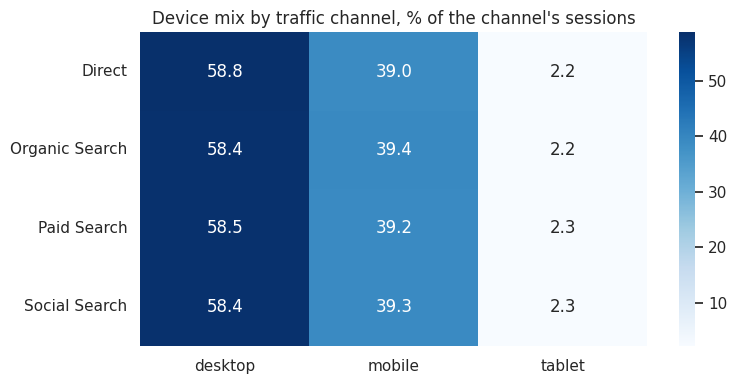

In [69]:
# Number of sessions by traffic channel and device type (rows with an undefined channel are ignored)
sessions_pivot = pd.pivot_table(df[df["traffic_channel"] != "Undefined"],
                                index="traffic_channel", columns="device",
                                values="session_id", aggfunc="nunique",
                                margins=True, margins_name="Total")
display(sessions_pivot)

# Device mix inside each channel (% of the channel's sessions) and each channel's share of all sessions
sessions_pct = sessions_pivot.div(sessions_pivot["Total"], axis=0) * 100
sessions_pct["Total"] = sessions_pivot["Total"] / sessions_pivot.loc["Total", "Total"] * 100
sessions_pct = sessions_pct.round(1).rename(columns={"Total": "% of all sessions"})
display(sessions_pct)

# Heatmap: device mix inside each channel (without the totals)
fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(sessions_pct.drop(index="Total", columns="% of all sessions"), annot=True, fmt=".1f", cmap="Blues", ax=ax)
ax.set(title="Device mix by traffic channel, % of the channel's sessions", xlabel="", ylabel="")
plt.tight_layout()
plt.show()

Sessions with an undefined channel (20,665) are excluded from this table. Organic Search brings the most sessions (119.7k, 37.9% of the sessions in the table), followed by Paid Search (90.7k, 28.8%), Direct (78.2k, 24.8%) and Social Search (26.8k, 8.5%). The largest single combination is Organic Search on desktop (69.9k sessions) and the smallest is Social Search on tablets (615).

The device mix is almost identical in every channel: about 58-59% desktop, 39% mobile and 2% tablet, as the identical rows of the heatmap show. So the device a visitor uses does not depend on how they arrive, and the differences between the cells reflect the size of each channel and device.

### 5.2 Sales by product category and country

country,United States,India,Canada,United Kingdom,France
product_category,,,,,
Sofas & armchairs,3707144.0,788430.0,692428.0,234812.0,187735.0
Chairs,2619774.0,544309.0,417741.0,188519.0,134029.0
Beds,2213058.0,358320.0,354772.0,133816.0,116414.0
Bookcases & shelving units,1567607.0,364507.0,278982.0,113988.0,73830.0
Cabinets & cupboards,994546.0,191888.0,181802.0,71684.0,59102.0
Outdoor furniture,929245.0,162289.0,185323.0,57002.0,40486.0
Tables & desks,777865.0,186158.0,132678.0,49374.0,42299.0
Chests of drawers & drawer units,382388.0,73111.0,71952.0,36784.0,21544.0
Bar furniture,330805.0,57657.0,51724.0,22103.0,11199.0


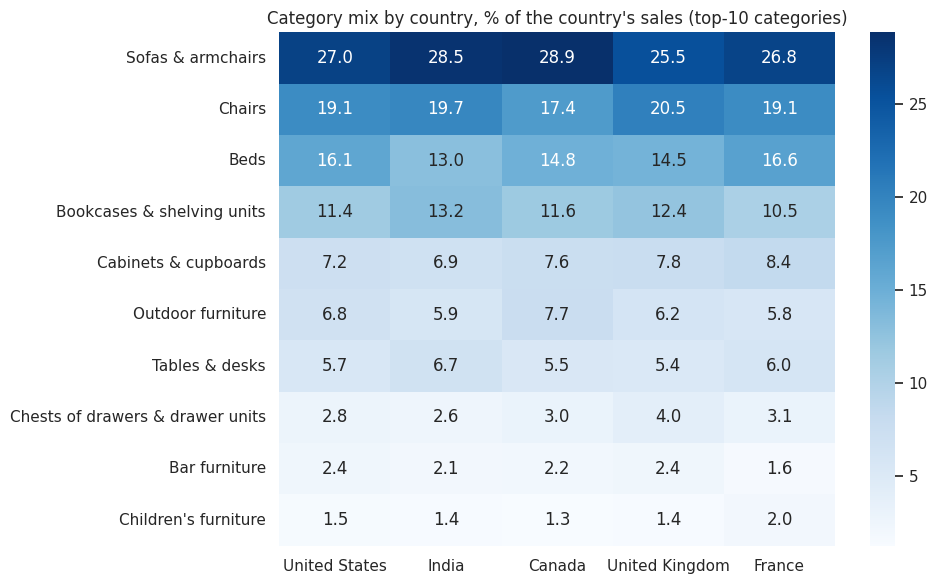

In [70]:
# Total sales by product category (top-10) and country (top-5)
sales_pivot = pd.pivot_table(df_orders[df_orders["product_category"].isin(top10_categories["product_category"])
                                       & df_orders["country"].isin(top5_countries_sales["country"])],
                             index="product_category", columns="country",
                             values="price", aggfunc="sum")

# Order rows and columns by total sales
sales_pivot = sales_pivot.loc[top10_categories["product_category"], top5_countries_sales["country"]]
display(sales_pivot.round(0))

# Category mix inside each country (% of the country's sales within the top-10 categories)
category_mix = sales_pivot.div(sales_pivot.sum()) * 100

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(category_mix, annot=True, fmt=".1f", cmap="Blues", ax=ax)
ax.set(title="Category mix by country, % of the country's sales (top-10 categories)", xlabel="", ylabel="")
plt.tight_layout()
plt.show()

The category mix is very similar across the five countries. Sofas & armchairs are the top category everywhere (25.5-28.9% of a country's sales) and Chairs are second (17.4-20.5%). Beds are third in every country except India, where Bookcases & shelving units are slightly ahead (13.2% vs 13.0%). The top three categories together make up about 60-63% of sales in each country.

The few visible differences are small: Canada sells relatively more Sofas & armchairs (28.9%) and Outdoor furniture (7.7%), the United Kingdom more Chests of drawers (4.0% vs 2.6-3.1% elsewhere), France more Beds (16.6%), and India more Bookcases & shelving units (13.2%). This confirms the earlier finding for the United States: the product structure of sales does not depend much on the country.

### 5.3 Weekly pattern by device type

device,desktop,mobile,tablet
weekday,,,
Monday,212340.0,135089.0,9208.0
Tuesday,246740.0,163153.0,9916.0
Wednesday,247818.0,163426.0,9260.0
Thursday,248990.0,152596.0,9826.0
Friday,224462.0,144277.0,8184.0
Saturday,168561.0,114928.0,6343.0
Sunday,151555.0,110841.0,4788.0


device,desktop,mobile,tablet
weekday,,,
Monday,-0.9,-4.0,12.0
Tuesday,15.1,15.9,20.6
Wednesday,15.6,16.1,12.6
Thursday,16.2,8.4,19.5
Friday,4.7,2.5,-0.5
Saturday,-21.4,-18.3,-22.8
Sunday,-29.3,-21.2,-41.8


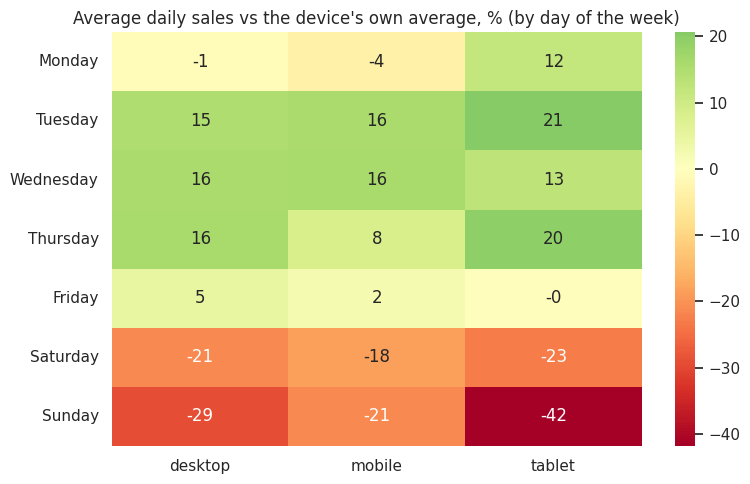

In [71]:
# Average daily sales by day of the week and device type
daily_device["weekday"] = daily_device["session_date"].dt.day_name()
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_device_pivot = pd.pivot_table(daily_device, index="weekday", columns="device",
                                      values="total_sales", aggfunc="mean").reindex(weekday_order)
display(weekday_device_pivot.round(0))

# Deviation from each device's average daily sales, %
device_avg = daily_device.groupby("device")["total_sales"].mean()
weekday_device_pct = ((weekday_device_pivot / device_avg - 1) * 100).round(1)
display(weekday_device_pct)

# Heatmap of the deviations
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(weekday_device_pct, annot=True, fmt=".0f", cmap="RdYlGn", center=0, ax=ax)
ax.set(title="Average daily sales vs the device's own average, % (by day of the week)", xlabel="", ylabel="")
plt.tight_layout()
plt.show()

The weekly pattern is the same on all three device types: Tuesday to Thursday are the strongest days (desktop and mobile are 8-16% above their own average), Monday and Friday are close to the average, and the weekend is the weakest. The weekend dip is somewhat smaller on mobile (Saturday -18%, Sunday -21%) than on desktop (-21% and -29%), so mobile holds up slightly better at weekends. Tablets show the same shape with larger swings (Sunday -42%), but their daily sales are small (about 5-10k), so these values are noisier.

### 5.4 Conversion by traffic channel and device type

device,desktop,mobile,tablet,Total
traffic_channel,,,,
Direct,4655,2985,160,7800
Organic Search,7011,4655,255,11921
Paid Search,5261,3574,207,9042
Social Search,1594,1065,57,2716
Total,18521,12279,679,31479


device,desktop,mobile,tablet,Total
traffic_channel,,,,
Direct,10.13,9.79,9.17,9.98
Organic Search,10.04,9.87,9.55,9.96
Paid Search,9.91,10.05,10.05,9.97
Social Search,10.18,10.10,9.27,10.13
Total,10.04,9.92,9.58,9.98


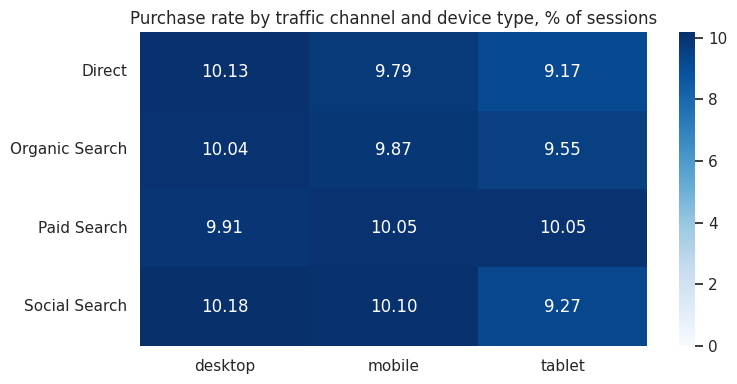

In [72]:
# Sessions with a purchase and purchase rate by traffic channel and device type (undefined channel ignored)
purchases_pivot = pd.pivot_table(df[df["traffic_channel"] != "Undefined"],
                                 index="traffic_channel", columns="device",
                                 values="price", aggfunc="count",
                                 margins=True, margins_name="Total")
display(purchases_pivot)

purchase_rate_pivot = (purchases_pivot / sessions_pivot * 100).round(2)
display(purchase_rate_pivot)

# Heatmap of purchase rates (without the totals)
fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(purchase_rate_pivot.drop(index="Total", columns="Total"), annot=True, fmt=".2f", cmap="Blues", vmin=0, ax=ax)
ax.set(title="Purchase rate by traffic channel and device type, % of sessions", xlabel="", ylabel="")
plt.tight_layout()
plt.show()

Conversion is practically the same in every combination of traffic channel and device type: the purchase rate ranges from 9.17% to 10.18%, around the overall 9.98%. For desktop and mobile in all four channels it stays within a narrow range of 9.79-10.18%, so no channel-device combination converts noticeably better than the others. Tablets are slightly lower in three channels (9.17-9.55% in Direct, Organic Search and Social Search), but they have the fewest sessions (615-2,669 per channel), so these differences are likely random. This agrees with the earlier results for channels and devices taken separately.

## 6. Correlation Analysis

In this section, we check how strongly different series move together and whether the relationships are statistically significant. We start with daily sessions and daily sales, then compare daily sales across continents, traffic channels and product categories.

### 6.1 Sessions and sales by date

Days: 88 | Pearson r = 0.93 (p = 1.74e-39) | Spearman rho = 0.90 (p = 1.54e-33)


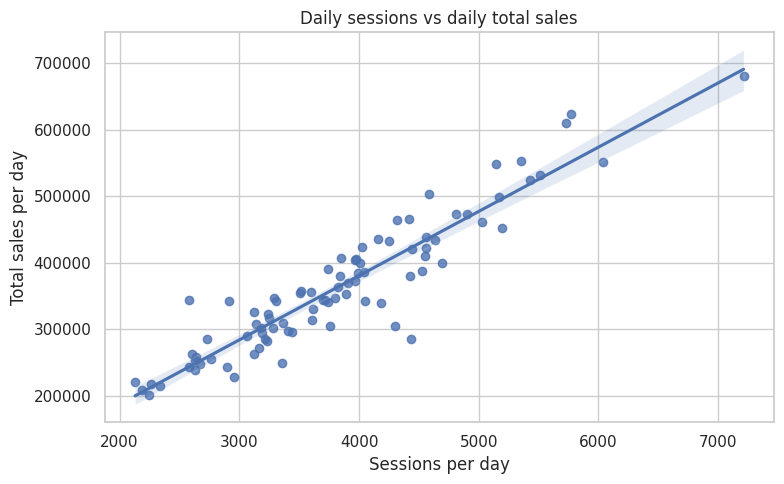

In [73]:
# Daily number of sessions and daily total sales
daily_sessions = df.groupby("session_date").agg(sessions=("session_id", "nunique")).reset_index()
sessions_sales = daily_sessions.merge(daily_sales[["session_date", "total_sales"]], on="session_date")

# Correlation coefficients and their p-values
r, p = stats.pearsonr(sessions_sales["sessions"], sessions_sales["total_sales"])
rho, p_s = stats.spearmanr(sessions_sales["sessions"], sessions_sales["total_sales"])
print(f"Days: {len(sessions_sales)} | Pearson r = {r:.2f} (p = {p:.3g}) | Spearman rho = {rho:.2f} (p = {p_s:.3g})")

# Scatter plot with a regression line
fig, ax = plt.subplots(figsize=(8, 5))
sns.regplot(data=sessions_sales, x="sessions", y="total_sales", ax=ax)
ax.set(title="Daily sessions vs daily total sales", xlabel="Sessions per day", ylabel="Total sales per day")
plt.tight_layout()
plt.show()

Daily sales closely follow the number of sessions: the more visitors on a given day, the higher the sales (Pearson r = 0.93, Spearman rho = 0.90, p < 0.001, 88 days). The two coefficients are close, so the relationship does not depend on a few extreme days. On average, one session generates about 95 in sales (total sales divided by the number of sessions). This means the December peak and the weak weekends seen earlier are largely explained by changes in traffic.

### 6.2 Correlation of sales between continents

Americas - Asia:   r = 0.69 (p = 8e-14)
Americas - Europe: r = 0.67 (p = 9.91e-13)
Asia - Europe:     r = 0.67 (p = 1.19e-12)


continent,Americas,Asia,Europe
continent,,,
Americas,1.00,0.67,0.63
Asia,0.67,1.00,0.61
Europe,0.63,0.61,1.00


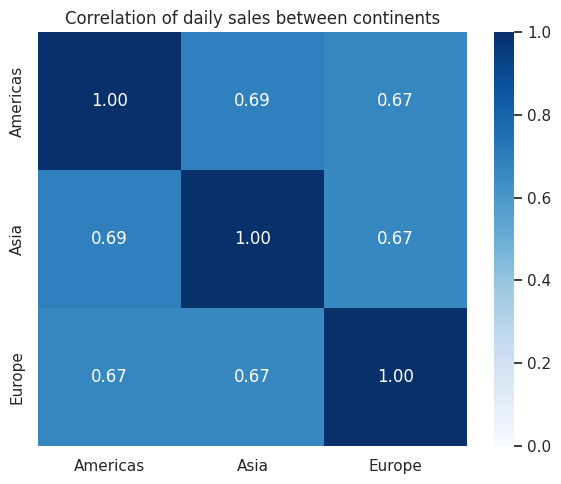

In [74]:
# Daily sales of the top-3 continents side by side
continent_wide = daily_continent.pivot(index="session_date", columns="continent", values="total_sales")

# Pearson correlation coefficients and p-values for each pair
r_am_as, p_am_as = stats.pearsonr(continent_wide["Americas"], continent_wide["Asia"])
r_am_eu, p_am_eu = stats.pearsonr(continent_wide["Americas"], continent_wide["Europe"])
r_as_eu, p_as_eu = stats.pearsonr(continent_wide["Asia"], continent_wide["Europe"])
print(f"Americas - Asia:   r = {r_am_as:.2f} (p = {p_am_as:.3g})")
print(f"Americas - Europe: r = {r_am_eu:.2f} (p = {p_am_eu:.3g})")
print(f"Asia - Europe:     r = {r_as_eu:.2f} (p = {p_as_eu:.3g})")

# Spearman correlation matrix for comparison
display(continent_wide.corr(method="spearman").round(2))

# Pearson correlation matrix as a heatmap
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(continent_wide.corr(), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax)
ax.set(title="Correlation of daily sales between continents", xlabel="", ylabel="")
plt.tight_layout()
plt.show()

Daily sales of the three continents are positively and significantly correlated: Pearson r is 0.69 for Americas-Asia and 0.67 for both Americas-Europe and Asia-Europe (all p < 0.001, 88 days). The Spearman coefficients are slightly lower (0.61-0.67) but show the same picture, so the result does not depend on a few extreme days. The relationship is moderately strong, not perfect: the continents move together because they share the same rhythm (the December peak, the Christmas dip and the weekly cycle), but each of them also has its own day-to-day fluctuations. All three pairs have almost the same correlation, so no continent moves apart from the others.

### 6.3 Correlation of sales between traffic channels

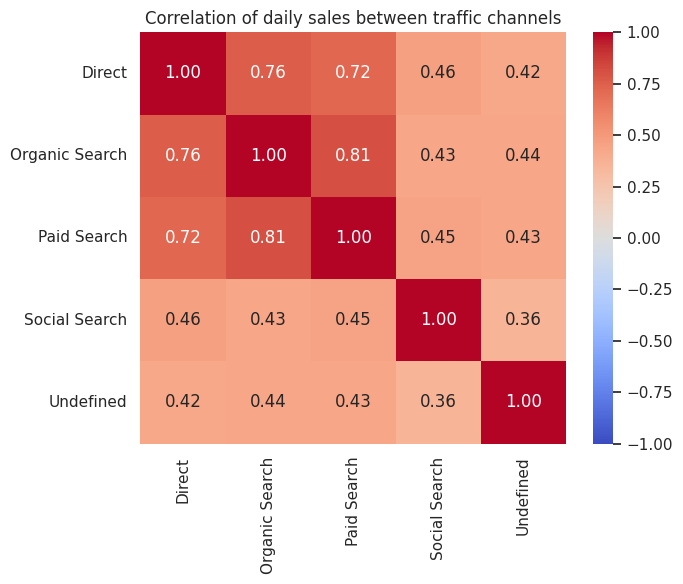

Direct - Organic Search:        r = 0.76 (p = 9.11e-18)
Direct - Paid Search:           r = 0.72 (p = 1.51e-15)
Direct - Social Search:         r = 0.46 (p = 5.9e-06)
Direct - Undefined:             r = 0.42 (p = 3.84e-05)
Organic Search - Paid Search:   r = 0.81 (p = 1.76e-21)
Organic Search - Social Search: r = 0.43 (p = 2.35e-05)
Organic Search - Undefined:     r = 0.44 (p = 2.24e-05)
Paid Search - Social Search:    r = 0.45 (p = 9.7e-06)
Paid Search - Undefined:        r = 0.43 (p = 2.9e-05)
Social Search - Undefined:      r = 0.36 (p = 0.000585)


traffic_channel,Direct,Organic Search,Paid Search,Social Search,Undefined
traffic_channel,,,,,
Direct,1.00,0.75,0.69,0.39,0.49
Organic Search,0.75,1.00,0.76,0.38,0.46
Paid Search,0.69,0.76,1.00,0.42,0.49
Social Search,0.39,0.38,0.42,1.00,0.39
Undefined,0.49,0.46,0.49,0.39,1.00


In [75]:
# Daily sales of the traffic channels side by side
channel_wide = daily_channel.pivot(index="session_date", columns="traffic_channel", values="total_sales")

# Pearson correlation matrix as a heatmap
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(channel_wide.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set(title="Correlation of daily sales between traffic channels", xlabel="", ylabel="")
plt.tight_layout()
plt.show()

# Pearson correlation coefficients and p-values for each pair of channels
r, p = stats.pearsonr(channel_wide["Direct"], channel_wide["Organic Search"])
print(f"Direct - Organic Search:        r = {r:.2f} (p = {p:.3g})")
r, p = stats.pearsonr(channel_wide["Direct"], channel_wide["Paid Search"])
print(f"Direct - Paid Search:           r = {r:.2f} (p = {p:.3g})")
r, p = stats.pearsonr(channel_wide["Direct"], channel_wide["Social Search"])
print(f"Direct - Social Search:         r = {r:.2f} (p = {p:.3g})")
r, p = stats.pearsonr(channel_wide["Direct"], channel_wide["Undefined"])
print(f"Direct - Undefined:             r = {r:.2f} (p = {p:.3g})")
r, p = stats.pearsonr(channel_wide["Organic Search"], channel_wide["Paid Search"])
print(f"Organic Search - Paid Search:   r = {r:.2f} (p = {p:.3g})")
r, p = stats.pearsonr(channel_wide["Organic Search"], channel_wide["Social Search"])
print(f"Organic Search - Social Search: r = {r:.2f} (p = {p:.3g})")
r, p = stats.pearsonr(channel_wide["Organic Search"], channel_wide["Undefined"])
print(f"Organic Search - Undefined:     r = {r:.2f} (p = {p:.3g})")
r, p = stats.pearsonr(channel_wide["Paid Search"], channel_wide["Social Search"])
print(f"Paid Search - Social Search:    r = {r:.2f} (p = {p:.3g})")
r, p = stats.pearsonr(channel_wide["Paid Search"], channel_wide["Undefined"])
print(f"Paid Search - Undefined:        r = {r:.2f} (p = {p:.3g})")
r, p = stats.pearsonr(channel_wide["Social Search"], channel_wide["Undefined"])
print(f"Social Search - Undefined:      r = {r:.2f} (p = {p:.3g})")

# Spearman correlation matrix for comparison
display(channel_wide.corr(method="spearman").round(2))

Daily sales of all traffic channels are positively correlated, and every pair is statistically significant (Pearson correlation, all p < 0.001, below the Bonferroni-corrected threshold of 0.005 for 10 comparisons). The three largest channels move most closely together: Organic Search and Paid Search (r = 0.81), Direct and Organic Search (r = 0.76), and Direct and Paid Search (r = 0.72). Social Search and Undefined are correlated with all other channels less strongly (r = 0.36-0.46), which is expected for small channels with noisier daily sales. Spearman coefficients give the same picture (rho = 0.38-0.76). No channel moves against the others: they all follow the same rhythm of peaks and dips.

### 6.4 Correlation of sales between product categories

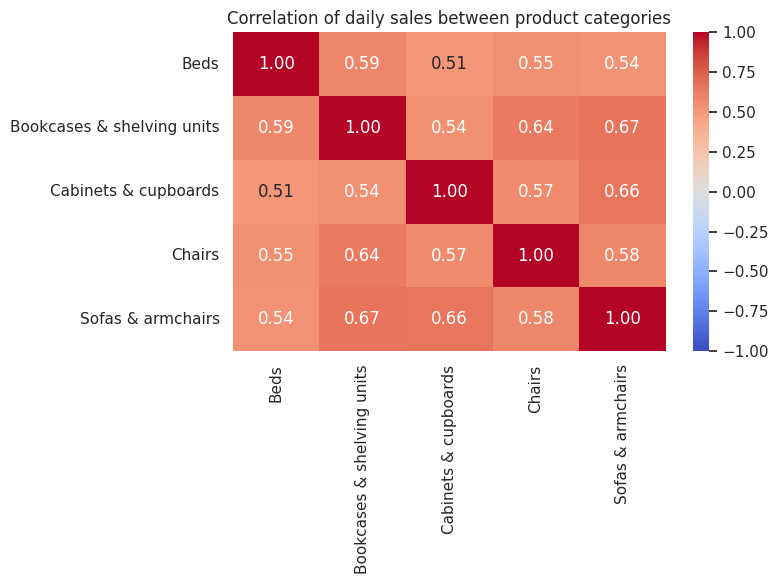

Beds - Bookcases & shelving units:              r = 0.59 (p = 1.15e-09)
Beds - Cabinets & cupboards:                    r = 0.51 (p = 2.91e-07)
Beds - Chairs:                                  r = 0.55 (p = 2.08e-08)
Beds - Sofas & armchairs:                       r = 0.54 (p = 7.69e-08)
Bookcases & shelving units - Cabinets & cupboards: r = 0.54 (p = 5.87e-08)
Bookcases & shelving units - Chairs:            r = 0.64 (p = 2.5e-11)
Bookcases & shelving units - Sofas & armchairs: r = 0.67 (p = 1.41e-12)
Cabinets & cupboards - Chairs:                  r = 0.57 (p = 5.47e-09)
Cabinets & cupboards - Sofas & armchairs:       r = 0.66 (p = 3.42e-12)
Chairs - Sofas & armchairs:                     r = 0.58 (p = 3.64e-09)


product_category,Beds,Bookcases & shelving units,Cabinets & cupboards,Chairs,Sofas & armchairs
product_category,,,,,
Beds,1.00,0.54,0.44,0.53,0.52
Bookcases & shelving units,0.54,1.00,0.53,0.64,0.63
Cabinets & cupboards,0.44,0.53,1.00,0.53,0.63
Chairs,0.53,0.64,0.53,1.00,0.58
Sofas & armchairs,0.52,0.63,0.63,0.58,1.00


In [76]:
# Daily sales of the top-5 categories side by side
category_wide = pd.pivot_table(df_orders[df_orders["product_category"].isin(top10_categories["product_category"].head(5))],
                               index="session_date", columns="product_category",
                               values="price", aggfunc="sum", fill_value=0)

# Pearson correlation matrix as a heatmap
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(category_wide.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set(title="Correlation of daily sales between product categories", xlabel="", ylabel="")
plt.tight_layout()
plt.show()

# Pearson correlation coefficients and p-values for each pair of categories
r, p = stats.pearsonr(category_wide["Beds"], category_wide["Bookcases & shelving units"])
print(f"Beds - Bookcases & shelving units:              r = {r:.2f} (p = {p:.3g})")
r, p = stats.pearsonr(category_wide["Beds"], category_wide["Cabinets & cupboards"])
print(f"Beds - Cabinets & cupboards:                    r = {r:.2f} (p = {p:.3g})")
r, p = stats.pearsonr(category_wide["Beds"], category_wide["Chairs"])
print(f"Beds - Chairs:                                  r = {r:.2f} (p = {p:.3g})")
r, p = stats.pearsonr(category_wide["Beds"], category_wide["Sofas & armchairs"])
print(f"Beds - Sofas & armchairs:                       r = {r:.2f} (p = {p:.3g})")
r, p = stats.pearsonr(category_wide["Bookcases & shelving units"], category_wide["Cabinets & cupboards"])
print(f"Bookcases & shelving units - Cabinets & cupboards: r = {r:.2f} (p = {p:.3g})")
r, p = stats.pearsonr(category_wide["Bookcases & shelving units"], category_wide["Chairs"])
print(f"Bookcases & shelving units - Chairs:            r = {r:.2f} (p = {p:.3g})")
r, p = stats.pearsonr(category_wide["Bookcases & shelving units"], category_wide["Sofas & armchairs"])
print(f"Bookcases & shelving units - Sofas & armchairs: r = {r:.2f} (p = {p:.3g})")
r, p = stats.pearsonr(category_wide["Cabinets & cupboards"], category_wide["Chairs"])
print(f"Cabinets & cupboards - Chairs:                  r = {r:.2f} (p = {p:.3g})")
r, p = stats.pearsonr(category_wide["Cabinets & cupboards"], category_wide["Sofas & armchairs"])
print(f"Cabinets & cupboards - Sofas & armchairs:       r = {r:.2f} (p = {p:.3g})")
r, p = stats.pearsonr(category_wide["Chairs"], category_wide["Sofas & armchairs"])
print(f"Chairs - Sofas & armchairs:                     r = {r:.2f} (p = {p:.3g})")

# Spearman correlation matrix for comparison
display(category_wide.corr(method="spearman").round(2))

Daily sales of the top-5 categories are positively correlated, and every pair is statistically significant (Pearson correlation, all p < 0.001, below the Bonferroni-corrected threshold of 0.005 for 10 comparisons). The coefficients range from r = 0.51 to r = 0.67. The strongest relationships are Sofas & armchairs with Bookcases & shelving units (r = 0.67) and with Cabinets & cupboards (r = 0.66); the weakest is Beds with Cabinets & cupboards (r = 0.51). Spearman coefficients are similar (rho = 0.44-0.64). There are no negative correlations, so the categories do not replace each other: they sell well on the same days, mostly because they all depend on the overall traffic.

### 6.5 Do busier days convert differently?

Sessions vs purchase rate:       Pearson r = -0.15 (p = 0.166) | Spearman rho = -0.13 (p = 0.226)
Sessions vs average order value: Pearson r = 0.11 (p = 0.290) | Spearman rho = 0.15 (p = 0.164)


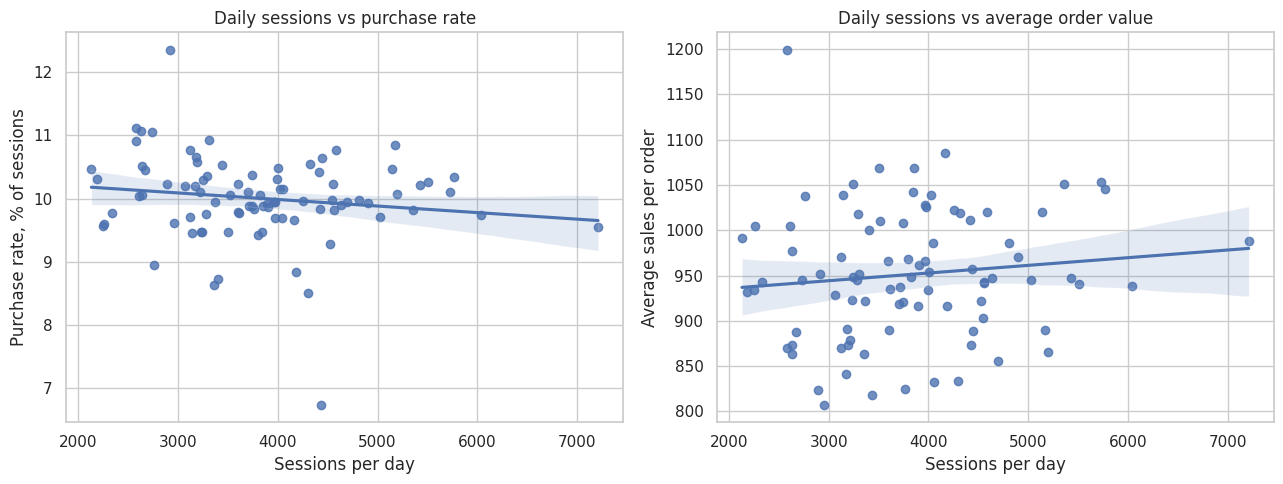

In [77]:
# Daily conversion and average order value
daily_kpi = daily_sessions.merge(daily_sales[["session_date", "total_sales", "orders"]], on="session_date")
daily_kpi["purchase_rate_pct"] = daily_kpi["orders"] / daily_kpi["sessions"] * 100
daily_kpi["avg_order_value"] = daily_kpi["total_sales"] / daily_kpi["orders"]

# Do busier days convert better or worse, and do they have larger orders?
r_rate, p_rate = stats.pearsonr(daily_kpi["sessions"], daily_kpi["purchase_rate_pct"])
rho_rate, p_rate_s = stats.spearmanr(daily_kpi["sessions"], daily_kpi["purchase_rate_pct"])
r_aov, p_aov = stats.pearsonr(daily_kpi["sessions"], daily_kpi["avg_order_value"])
rho_aov, p_aov_s = stats.spearmanr(daily_kpi["sessions"], daily_kpi["avg_order_value"])
print(f"Sessions vs purchase rate:       Pearson r = {r_rate:.2f} (p = {p_rate:.3f}) | Spearman rho = {rho_rate:.2f} (p = {p_rate_s:.3f})")
print(f"Sessions vs average order value: Pearson r = {r_aov:.2f} (p = {p_aov:.3f}) | Spearman rho = {rho_aov:.2f} (p = {p_aov_s:.3f})")

# Scatter plots with regression lines
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.regplot(data=daily_kpi, x="sessions", y="purchase_rate_pct", ax=axes[0])
axes[0].set(title="Daily sessions vs purchase rate", xlabel="Sessions per day", ylabel="Purchase rate, % of sessions")
sns.regplot(data=daily_kpi, x="sessions", y="avg_order_value", ax=axes[1])
axes[1].set(title="Daily sessions vs average order value", xlabel="Sessions per day", ylabel="Average sales per order")
plt.tight_layout()
plt.show()

Busier days do not convert differently and do not have larger orders. The relationship between daily sessions and the purchase rate is weak and not statistically significant (Pearson r = -0.15, p = 0.17; Spearman rho = -0.13, p = 0.23), and the same holds for the average order value (r = 0.11, p = 0.29; rho = 0.15, p = 0.16). The purchase rate stays at about 10% (mostly between 8.5% and 11%) and the average order at about 950 whether the day has 2,000 or 7,000 sessions. This explains why daily sales are so closely tied to traffic: more visitors simply mean more purchases of the same size.

**Conclusions for section 6.** Daily sales are very strongly tied to the number of sessions (r = 0.93), because the purchase rate (about 10%) and the average order (about 950) do not depend on how busy the day is. Daily sales across continents (r = 0.67-0.69), traffic channels (0.36-0.81) and the top-5 product categories (0.51-0.67) are positively and significantly correlated in every pair, and there are no negative correlations: segments do not replace each other, they move together following the same rhythm of traffic. The correlations are strongest between the largest segments and weaker for the small, noisier ones (Social Search, Undefined).

## 7. Comparison of Groups

In this section, we use statistical tests to check whether the differences between groups are real or random: registered and unregistered users (daily sales), traffic channels (daily sessions) and the share of organic traffic in Europe and the Americas.

### 7.1 Daily sales: registered vs unregistered users

Days in each sample: 88 | 88


,registered,unregistered
count,88.0,88.0
mean,29347.0,333968.0
std,10765.0,92910.0
min,11779.0,182206.0
25%,20717.0,270486.0
50%,28048.0,316724.0
75%,35775.0,379948.0
max,68151.0,612358.0


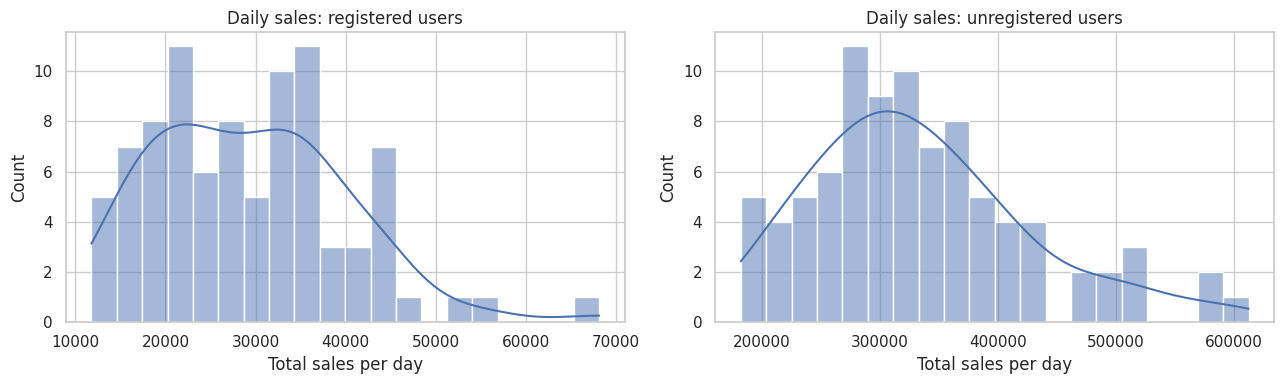

Shapiro-Wilk: registered p = 0.007 | unregistered p = 0.003
Wilcoxon signed-rank test: p = 3.73e-16 | days when registered users spent more: 0 of 88


In [78]:
# Samples: daily sales of registered and unregistered users
df["is_registered"] = df["registered_user_id"].notna()
daily_groups = (df.groupby(["session_date", "is_registered"])
                .agg(total_sales=("price", "sum"), sessions=("session_id", "nunique"))
                .reset_index())
registered_sales = daily_groups.loc[daily_groups["is_registered"], "total_sales"]
guest_sales = daily_groups.loc[~daily_groups["is_registered"], "total_sales"]

print(f"Days in each sample: {len(registered_sales)} | {len(guest_sales)}")
display(pd.DataFrame({"registered": registered_sales.describe(), "unregistered": guest_sales.describe()}).round(0))

# Distributions of both samples
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(registered_sales, kde=True, bins=20, ax=axes[0])
axes[0].set(title="Daily sales: registered users", xlabel="Total sales per day")
sns.histplot(guest_sales, kde=True, bins=20, ax=axes[1])
axes[1].set(title="Daily sales: unregistered users", xlabel="Total sales per day")
plt.tight_layout()
plt.show()

# Normality check (Shapiro-Wilk)
w_reg, p_reg = stats.shapiro(registered_sales)
w_guest, p_guest = stats.shapiro(guest_sales)
print(f"Shapiro-Wilk: registered p = {p_reg:.3f} | unregistered p = {p_guest:.3f}")

# Both samples cover the same 88 days, so we compare them day by day (Wilcoxon signed-rank test)
stat, p = stats.wilcoxon(registered_sales, guest_sales)
days_registered_higher = (registered_sales.to_numpy() > guest_sales.to_numpy()).sum()
print(f"Wilcoxon signed-rank test: p = {p:.3g} | days when registered users spent more: {days_registered_higher} of {len(registered_sales)}")

On every one of the 88 days, unregistered users generated more sales than registered users: an average day brings about 334k from unregistered users and 29k from registered ones, roughly 11 times more. Neither sample is normally distributed (Shapiro-Wilk p = 0.007 and 0.003), so we compared them day by day with the non-parametric Wilcoxon signed-rank test, which gave p < 0.001 (registered users spent more on 0 of 88 days). The difference is statistically significant, but it mainly reflects the size of the groups: registered users make up only about 8% of sessions, so they naturally bring about 8% of sales. A fairer comparison of their behavior is sales per session, shown next.

### 7.2 Daily sales per session: registered vs unregistered users

,registered,unregistered
count,88.0,88.0
mean,92.7,95.4
std,26.5,9.6
min,42.1,65.3
25%,73.6,89.9
50%,90.8,94.9
75%,108.4,100.9
max,201.8,126.9


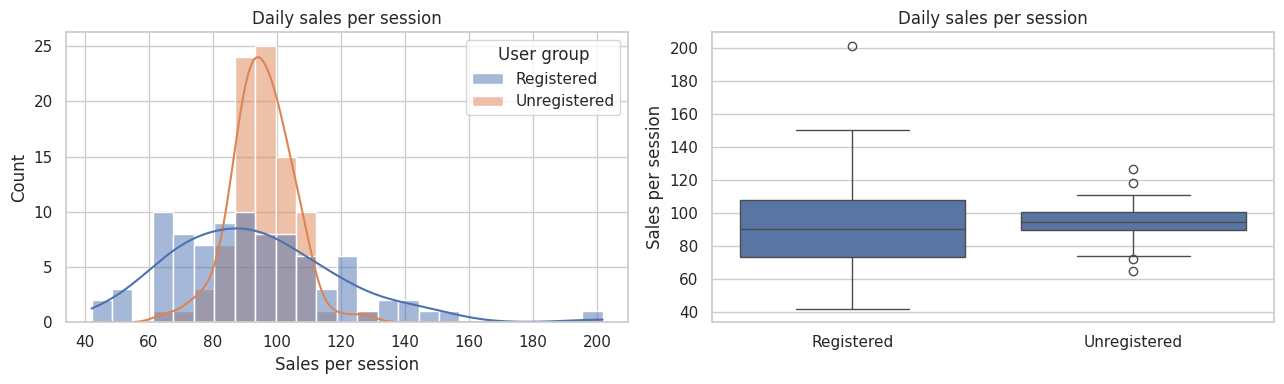

Shapiro-Wilk: registered p = 0.003 | unregistered p = 0.240
Wilcoxon signed-rank test: p = 0.134 | days when registered users spent more per session: 35 of 88
Median sales per session: registered 90.8 vs unregistered 94.9 (-4.2%)


In [79]:
# Samples: daily sales per session for each group
daily_groups["sales_per_session"] = daily_groups["total_sales"] / daily_groups["sessions"]
registered_sps = daily_groups.loc[daily_groups["is_registered"], "sales_per_session"]
guest_sps = daily_groups.loc[~daily_groups["is_registered"], "sales_per_session"]
display(pd.DataFrame({"registered": registered_sps.describe(), "unregistered": guest_sps.describe()}).round(1))

# Distributions of both samples
daily_groups["user_group"] = daily_groups["is_registered"].map({True: "Registered", False: "Unregistered"})
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=daily_groups, x="sales_per_session", hue="user_group", hue_order=["Registered", "Unregistered"],
             kde=True, bins=25, ax=axes[0])
axes[0].set(title="Daily sales per session", xlabel="Sales per session")
axes[0].get_legend().set_title("User group")
sns.boxplot(data=daily_groups, x="user_group", order=["Registered", "Unregistered"], y="sales_per_session", ax=axes[1])
axes[1].set(title="Daily sales per session", xlabel="", ylabel="Sales per session")
plt.tight_layout()
plt.show()

# Normality check (Shapiro-Wilk)
w_reg, p_reg = stats.shapiro(registered_sps)
w_guest, p_guest = stats.shapiro(guest_sps)
print(f"Shapiro-Wilk: registered p = {p_reg:.3f} | unregistered p = {p_guest:.3f}")

# Same 88 days in both samples, so we compare day by day (Wilcoxon signed-rank test)
stat, p = stats.wilcoxon(registered_sps, guest_sps)
days_higher = (registered_sps.to_numpy() > guest_sps.to_numpy()).sum()
median_diff = (registered_sps.median() / guest_sps.median() - 1) * 100
print(f"Wilcoxon signed-rank test: p = {p:.3f} | days when registered users spent more per session: {days_higher} of {len(registered_sps)}")
print(f"Median sales per session: registered {registered_sps.median():.1f} vs unregistered {guest_sps.median():.1f} ({median_diff:+.1f}%)")

Per session, registered and unregistered users bring almost the same amount of sales: the median is 90.8 for registered users and 94.9 for unregistered users (-4.2%). The difference is not statistically significant (Wilcoxon signed-rank test, p = 0.134), and registered users had higher sales per session on 35 of 88 days. The registered group is much more variable (standard deviation 26.5 vs 9.6, with a few very high days), because each day is based on only about 300 sessions, so one expensive purchase can noticeably change the daily average. Together with the previous test, this means that registered users generate fewer total sales only because there are fewer of them; there is no evidence that each of their sessions is worth less.

### 7.3 Daily sessions by traffic channel

traffic_channel,Direct,Organic Search,Paid Search,Social Search
count,88.0,88.0,88.0,88.0
mean,888.0,1360.0,1031.0,305.0
std,222.0,340.0,257.0,89.0
min,481.0,733.0,578.0,137.0
25%,745.0,1120.0,875.0,238.0
50%,870.0,1332.0,1000.0,310.0
75%,1012.0,1570.0,1184.0,358.0
max,1668.0,2589.0,1959.0,561.0


,0
traffic_channel,
Direct,0.69
Organic Search,0.73
Paid Search,0.79
Social Search,0.41


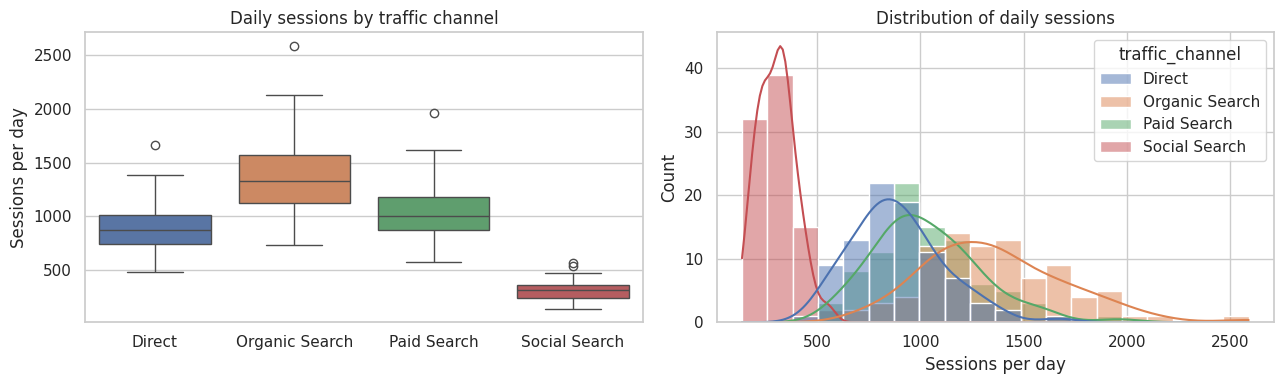

Shapiro-Wilk: Direct p = 0.0468 | Organic Search p = 0.0232 | Paid Search p = 0.0165 | Social Search p = 0.177
Friedman test: chi-square = 264.0, p = 6.13e-57
Direct vs Organic Search:         p = 3.73e-16, adjusted p = 2.24e-15
Direct vs Paid Search:            p = 3.72e-16, adjusted p = 2.23e-15
Direct vs Social Search:          p = 3.73e-16, adjusted p = 2.24e-15
Organic Search vs Paid Search:    p = 3.73e-16, adjusted p = 2.24e-15
Organic Search vs Social Search:  p = 3.73e-16, adjusted p = 2.24e-15
Paid Search vs Social Search:     p = 3.73e-16, adjusted p = 2.24e-15


In [80]:
# Daily number of sessions for each traffic channel (undefined channel excluded)
daily_channel_sessions = (df[df["traffic_channel"] != "Undefined"]
                          .pivot_table(index="session_date", columns="traffic_channel",
                                       values="session_id", aggfunc="nunique"))
display(daily_channel_sessions.describe().round(0))
display(daily_channel_sessions.skew().round(2))

# Distributions of the samples
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=daily_channel_sessions, ax=axes[0])
axes[0].set(title="Daily sessions by traffic channel", xlabel="", ylabel="Sessions per day")
sns.histplot(data=daily_channel_sessions, kde=True, bins=20, ax=axes[1])
axes[1].set(title="Distribution of daily sessions", xlabel="Sessions per day")
plt.tight_layout()
plt.show()

# Normality check for each channel (p < 0.05 means the distribution is not normal)
p_norm_dir = stats.shapiro(daily_channel_sessions["Direct"]).pvalue
p_norm_org = stats.shapiro(daily_channel_sessions["Organic Search"]).pvalue
p_norm_paid = stats.shapiro(daily_channel_sessions["Paid Search"]).pvalue
p_norm_soc = stats.shapiro(daily_channel_sessions["Social Search"]).pvalue
print(f"Shapiro-Wilk: Direct p = {p_norm_dir:.3g} | Organic Search p = {p_norm_org:.3g} | "
      f"Paid Search p = {p_norm_paid:.3g} | Social Search p = {p_norm_soc:.3g}")

# All channels are measured on the same 88 days, so we use the Friedman test (paired test for 3+ groups)
stat, p = stats.friedmanchisquare(*daily_channel_sessions.T.to_numpy())
print(f"Friedman test: chi-square = {stat:.1f}, p = {p:.3g}")

# Post-hoc test: Wilcoxon signed-rank test for each pair of channels
p_dir_org = stats.wilcoxon(daily_channel_sessions["Direct"], daily_channel_sessions["Organic Search"]).pvalue
p_dir_paid = stats.wilcoxon(daily_channel_sessions["Direct"], daily_channel_sessions["Paid Search"]).pvalue
p_dir_soc = stats.wilcoxon(daily_channel_sessions["Direct"], daily_channel_sessions["Social Search"]).pvalue
p_org_paid = stats.wilcoxon(daily_channel_sessions["Organic Search"], daily_channel_sessions["Paid Search"]).pvalue
p_org_soc = stats.wilcoxon(daily_channel_sessions["Organic Search"], daily_channel_sessions["Social Search"]).pvalue
p_paid_soc = stats.wilcoxon(daily_channel_sessions["Paid Search"], daily_channel_sessions["Social Search"]).pvalue

# Bonferroni correction: 6 comparisons, so each p-value is multiplied by 6
print(f"Direct vs Organic Search:         p = {p_dir_org:.3g}, adjusted p = {min(p_dir_org * 6, 1):.3g}")
print(f"Direct vs Paid Search:            p = {p_dir_paid:.3g}, adjusted p = {min(p_dir_paid * 6, 1):.3g}")
print(f"Direct vs Social Search:          p = {p_dir_soc:.3g}, adjusted p = {min(p_dir_soc * 6, 1):.3g}")
print(f"Organic Search vs Paid Search:    p = {p_org_paid:.3g}, adjusted p = {min(p_org_paid * 6, 1):.3g}")
print(f"Organic Search vs Social Search:  p = {p_org_soc:.3g}, adjusted p = {min(p_org_soc * 6, 1):.3g}")
print(f"Paid Search vs Social Search:     p = {p_paid_soc:.3g}, adjusted p = {min(p_paid_soc * 6, 1):.3g}")

The channels differ clearly in the number of daily sessions: Organic Search brings the most (median 1,332 per day), followed by Paid Search (1,000), Direct (870) and Social Search (310). The daily sessions of every channel are right-skewed (skewness 0.4-0.8). The Shapiro-Wilk test rejects normality for Organic Search (p = 0.023) and Paid Search (p = 0.017), and for Direct the result is just below the threshold (p = 0.047); Social Search does not deviate significantly from a normal distribution (p = 0.18). Because not all samples are normal and all channels are measured on the same 88 days, we used the non-parametric Friedman test for paired samples. The differences are statistically significant (chi-square = 264.0, p < 0.001).

To find out which channels differ, we compared every pair with the Wilcoxon signed-rank test and applied the Bonferroni correction for 6 comparisons. All six pairs differ significantly (all adjusted p < 0.001), so the order Organic Search > Paid Search > Direct > Social Search is confirmed for every pair of channels.

### 7.4 Share of organic traffic: Europe vs the Americas

In [81]:
# Input data: sessions and organic sessions in Europe and the Americas
df["is_organic"] = df["traffic_channel"] == "Organic Search"
organic_input = (df[df["continent"].isin(["Europe", "Americas"])]
                 .groupby("continent")
                 .agg(sessions=("session_id", "nunique"), organic_sessions=("is_organic", "sum")))
organic_input["other_sessions"] = organic_input["sessions"] - organic_input["organic_sessions"]
organic_input["organic_share_pct"] = (organic_input["organic_sessions"] / organic_input["sessions"] * 100).round(2)
display(organic_input)

# Chi-square test for two proportions (2x2 table: organic / other sessions in each continent)
chi2, p, dof, expected = stats.chi2_contingency(organic_input[["organic_sessions", "other_sessions"]], correction=False)
print(f"Chi-square test: chi2 = {chi2:.2f}, p = {p:.3f}")

# Size of the difference with a 95% confidence interval
share = organic_input["organic_sessions"] / organic_input["sessions"]
diff = share["Europe"] - share["Americas"]
se = np.sqrt((share * (1 - share) / organic_input["sessions"]).sum())
print(f"Difference (Europe - Americas): {diff*100:.2f} pp, 95% CI [{(diff - 1.96*se)*100:.2f}; {(diff + 1.96*se)*100:.2f}]")

,sessions,organic_sessions,other_sessions,organic_share_pct
continent,,,,
Americas,185693,66074,119619,35.58
Europe,62687,22309,40378,35.59


Chi-square test: chi2 = 0.00, p = 0.980
Difference (Europe - Americas): 0.01 pp, 95% CI [-0.43; 0.44]


The share of organic traffic is practically the same in both regions: 35.58% of sessions in the Americas (66,074 of 185,693) and 35.59% in Europe (22,309 of 62,687). The difference of 0.01 percentage points is not statistically significant (chi-square test, p = 0.98), and the 95% confidence interval (from -0.43 to +0.44 pp) is narrow, so with this many sessions any real difference is likely smaller than half a percentage point. Visitors from Europe and the Americas come through organic search equally often.

### 7.5 Additional test: does the purchase rate depend on the group?

In [82]:
# Does the purchase rate depend on the group? (chi-square test of independence)
df["has_purchase"] = df["price"].notna()
top10_countries_df = df[df["country"].isin(top10_country_conversion["country"])]

chi2_channel, p_channel, _, _ = stats.chi2_contingency(pd.crosstab(df["traffic_channel"], df["has_purchase"]))
chi2_device, p_device, _, _ = stats.chi2_contingency(pd.crosstab(df["device"], df["has_purchase"]))
chi2_country, p_country, _, _ = stats.chi2_contingency(pd.crosstab(top10_countries_df["country"], top10_countries_df["has_purchase"]))
chi2_news, p_news, _, _ = stats.chi2_contingency(pd.crosstab(registered_users["is_newsletter_unsubscribed"], registered_users["price"].notna()), correction=False)

print(f"Traffic channel (5 groups):             chi2 = {chi2_channel:.2f}, p = {p_channel:.3f}")
print(f"Device type (3 groups):                 chi2 = {chi2_device:.2f}, p = {p_device:.3f}")
print(f"Country, top-10 by traffic (10 groups): chi2 = {chi2_country:.2f}, p = {p_country:.3f}")
print(f"Newsletter status, registered users:    chi2 = {chi2_news:.2f}, p = {p_news:.3f}")

Traffic channel (5 groups):             chi2 = 0.74, p = 0.947
Device type (3 groups):                 chi2 = 1.98, p = 0.372
Country, top-10 by traffic (10 groups): chi2 = 15.12, p = 0.088
Newsletter status, registered users:    chi2 = 1.66, p = 0.197


No significant dependence of the purchase rate was found for any of the tested groupings: traffic channel (chi-square = 0.74, p = 0.95), device type (1.98, p = 0.37), country among the top-10 (15.12, p = 0.09) and newsletter status of registered users (1.66, p = 0.20). All p-values are above 0.05, so the small differences seen in the earlier sections (for example, 10.06% vs 9.44% for subscribed and unsubscribed users) may be due to chance. Country is the closest to the threshold, but it is still not significant, and the purchase rates of the ten countries range only from 9.5% to 10.7%.

**Conclusions for section 7.** Registered users generate about 11 times fewer sales per day than unregistered users (Wilcoxon p < 0.001), but this reflects the size of the group: per session, the difference between registered and unregistered users is not significant (median 90.8 vs 94.9, p = 0.13). Traffic channels differ significantly in the number of daily sessions (Friedman test, p < 0.001), and pairwise Wilcoxon tests confirm the difference for every pair of channels. The share of organic traffic does not differ significantly between Europe and the Americas (about 35.6%, p = 0.98). For traffic channel, device, country and newsletter status, no significant differences in the purchase rate were found. In short, the segments differ mainly in size: for the metrics we tested, no significant differences in behavior were found.

## 8. Conclusions and Recommendations

The interactive dashboard with these results is available on [Tableau Public](https://public.tableau.com/app/profile/volodymyr.popeliastyi7905/viz/WebsiteAnalytics_17924856911650/Overview).

### Key findings

1. **Where sales come from.** The Americas generate 55% of sales and the United States alone 44%; the top-3 continents account for 98% of sales. The top-5 countries (United States, India, Canada, United Kingdom, France) are the same by sales, orders and registered users. Europe is more fragmented: its two largest countries make up only 28% of European sales.
2. **Products.** Sofas & armchairs, Chairs and Beds bring 61% of sales. Bookcases & shelving units have the most orders but a low average order (about 477 vs 1,950 for sofas). The category mix is practically the same in every top country.
3. **Channels and devices.** Organic Search (36% of sales), Paid Search (27%) and Direct (23%) lead; desktop gives 59% of sales and mobile 39%. The device mix is almost the same in every channel.
4. **Conversion is stable.** About 10% of sessions end with a purchase and 8% with a registration, and the average order is about 950. For channel, device, country and newsletter status, no significant differences in the purchase rate were found.
5. **Dynamics.** Sales peak in the second week of December (best day: December 8), fall to their lowest level around Christmas and recover in January. Tuesday to Thursday are 13-16% above the average day and weekends 20-26% below. Black Friday and Cyber Monday do not stand out. All continents, channels and categories move together, and daily sales follow the number of sessions very closely (r = 0.93).
6. **Registered users.** They make up about 8% of sessions; 72% confirmed their email and 17% unsubscribed from the newsletter. Their sales per session do not differ significantly from those of other visitors.

### Recommendations

1. **Grow traffic, since conversion is flat.** Sales rise and fall with the number of visitors, so traffic acquisition is the main lever; campaigns and stock should be planned around the December peak and the strong weekdays.
2. **Check the cost of paid traffic.** Paid Search converts at practically the same rate as Organic Search, so its value depends on cost per visitor, which is not in the data and should be compared before increasing the budget.
3. **Try to raise conversion itself.** A stable 10% across all segments suggests a site-wide factor; tests of the checkout, prices or the product page could lift every segment at once.
4. **Use the product mix.** Promote high-ticket categories (sofas, beds) and add cross-sell or bundles to high-volume, low-price categories such as bookcases.
5. **Reduce dependence on one market and improve email quality.** The United States gives 44% of sales, and 28% of registered users have not confirmed their email, which is worth fixing in the sign-up flow.

### Limitations

- The data cover only 88 days, so yearly seasonality cannot be assessed.
- Orders and accounts are recorded until January 27, 2021, and the last four days were removed.
- There is no data on advertising costs, so channel profitability cannot be judged.
- About 6% of sales have an undefined channel and 20% of sales an unknown device model.
- Each registered user appears with a single session, so repeat purchases are not visible.

## 9. Export for Tableau

In this section, we aggregate the cleaned data into one table for the Tableau dashboard and save it as a CSV file.

In [83]:
# Aggregated dataset for Tableau: one row per date x location x channel x device x product category
tableau_data = (df.assign(product_category=df["product_category"].fillna("No purchase"))
                .groupby(["session_date", "continent", "country", "traffic_channel", "device", "product_category"])
                .agg(sessions=("session_id", "nunique"),
                     registered_users=("registered_user_id", "count"),
                     purchases=("price", "count"),
                     sales=("price", "sum"))
                .reset_index())

# Check: totals must match the cleaned dataset
print(f"Sessions: {tableau_data['sessions'].sum():,} vs {df['session_id'].nunique():,}")
print(f"Registered users: {tableau_data['registered_users'].sum():,} vs {df['registered_user_id'].notna().sum():,}")
print(f"Purchases: {tableau_data['purchases'].sum():,} vs {df['price'].notna().sum():,}")
print(f"Sales: {tableau_data['sales'].sum():,.1f} vs {df['price'].sum():,.1f}")

# Save the table (the same file is stored in the repository as data/tableau_data.csv)
tableau_data.to_csv("tableau_data.csv", index=False)



Sessions: 336,076 vs 336,076
Registered users: 27,945 vs 27,945
Purchases: 33,538 vs 33,538
Sales: 31,971,731.1 vs 31,971,731.1
